# Statistical Arbitrage & Pairs Trading

## A Quantitative Framework Using Real Market Data with Out-of-Sample Testing

**Statistical arbitrage** exploits temporary mispricings between related securities
by taking offsetting long/short positions that profit from mean reversion of their
price relationship. Pairs trading, the simplest form of stat-arb, was pioneered by
Nunzio Tartaglia's quantitative group at Morgan Stanley in the mid-1980s.

### Core Premise: Mean Reversion of Spreads

If two assets share a common stochastic trend (i.e., they are **cointegrated**),
their price spread is stationary and mean-reverting. When the spread deviates
significantly from its long-run mean, the strategy will:
- **Go long the spread** (buy the underperformer, sell the outperformer) when the
  spread is unusually low
- **Go short the spread** when it is unusually high
- **Close** when the spread reverts to its mean

### Real-World Stock Pairs

This analysis uses **five real stock pairs** from Yahoo Finance, chosen for their
economic relationships:

| Pair | Tickers | Rationale |
|:-----|:--------|:----------|
| **Beverages** | KO / PEP | Coca-Cola vs PepsiCo — direct industry competitors |
| **Oil Majors** | XOM / CVX | ExxonMobil vs Chevron — common crude oil exposure |
| **Gold Sector** | GLD / GDX | SPDR Gold Trust vs Gold Miners ETF — related but structurally different |
| **Big Banks** | JPM / BAC | JPMorgan vs Bank of America — shared macro/rate sensitivity |
| **Big Tech** | MSFT / AAPL | Microsoft vs Apple — both mega-caps but different business models |

### Research Design: Formation vs. Trading Period

To avoid look-ahead bias, the sample is split in two:

| Period | Dates | Used for |
|:-------|:------|:---------|
| **Formation** (in-sample) | Jan 2019 – Dec 2021 | Cointegration tests, hedge ratios, OU and regime model estimation |
| **Trading** (out-of-sample) | Jan 2022 – Dec 2023 | Backtest only — no parameter is fitted on this data |

All strategy returns are expressed as a **percentage of gross exposure** and are
reported **net of transaction costs**.

### Topics Covered

1. Setup
2. Real market data acquisition (with synthetic fallback)
3. Engle-Granger and Johansen cointegration tests
4. Spread modeling with Ornstein-Uhlenbeck processes
5. Out-of-sample z-score pairs trading strategy
6. Rolling cointegration stability analysis
7. Half-life of mean reversion
8. Markov regime switching for adaptive trading
9. Monte Carlo robustness testing
10. Multi-pair portfolio construction
11. Conclusions

---

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from statsmodels.regression.linear_model import OLS
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

try:
    import yfinance as yf
    HAS_YFINANCE = True
except ImportError:
    HAS_YFINANCE = False
    print("yfinance not installed. Run: pip install yfinance")

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except Exception:
    try:
        plt.style.use('seaborn-whitegrid')
    except Exception:
        plt.style.use('ggplot')

print("All imports successful.")
print(f"  yfinance available: {HAS_YFINANCE}")

All imports successful.
  yfinance available: True


In [2]:
np.random.seed(42)

Z_ENTRY = 2.0
Z_EXIT = 0.5
Z_STOP = 3.0
LOOKBACK = 60

ROLL_WINDOW = 252

START_DATE = '2019-01-01'
END_DATE = '2024-01-01'
FORMATION_END = '2021-12-31'
TRADING_START = '2022-01-01'

TRANSACTION_COST = 0.0005
SIGNIFICANCE = 0.05
MIN_PAIRS = 3

COLORS = {
    'blue':    '#1e88e5',
    'red':     '#e53935',
    'green':   '#43a047',
    'orange':  '#fb8c00',
    'purple':  '#8e24aa',
    'teal':    '#00897b',
    'grey':    '#757575',
    'gold':    '#fdd835',
    'dark':    '#212121',
    'light':   '#f5f5f5',
}
PAIR_COLORS = [COLORS['blue'], COLORS['red'], COLORS['green'],
               COLORS['orange'], COLORS['purple']]

print("Configuration loaded.")
print(f"  Formation period: {START_DATE} to {FORMATION_END}")
print(f"  Trading period:   {TRADING_START} to {END_DATE} (end date exclusive)")
print(f"  Transaction cost: {TRANSACTION_COST * 1e4:.0f} bps of gross notional per position change")

Configuration loaded.
  Formation period: 2019-01-01 to 2021-12-31
  Trading period:   2022-01-01 to 2024-01-01 (end date exclusive)
  Transaction cost: 5 bps of gross notional per position change


## 2. Data Acquisition

### Real Market Data via Yahoo Finance

Daily closing prices adjusted for splits and dividends (`auto_adjust=True`) are
downloaded for five stock pairs from January 2019 to December 2023 (~5 years of
trading data). Each pair is chosen for its economic relationship — companies in the
same industry or asset class often share common risk factors that may create a
cointegrating relationship.

**Why these pairs?**

- **KO / PEP**: Both are global beverage giants with similar revenue drivers
  (consumer spending, commodity costs, emerging market demand).

- **XOM / CVX**: The two largest US-listed integrated oil companies. Their profits
  are driven by the same crude oil and natural gas prices.

- **GLD / GDX**: GLD tracks the spot price of gold; GDX holds gold mining stocks.
  Miners' earnings depend on gold prices, but operational leverage, cost structure,
  and management quality introduce idiosyncratic risk that may break cointegration.

- **JPM / BAC**: Both are large US money-center banks with exposure to interest
  rates, credit markets, and economic cycles.

- **MSFT / AAPL**: Both are mega-cap tech leaders, but with very different business
  models (enterprise software vs. consumer hardware/services). They may be highly
  correlated but **not** cointegrated — serving as a control pair.

If Yahoo Finance is unavailable, the notebook falls back to synthetic data generated
from known cointegration DGPs, and every result below is then labelled as synthetic.

In [3]:
PAIR_TICKERS = [
    ('KO', 'PEP'),
    ('XOM', 'CVX'),
    ('GLD', 'GDX'),
    ('JPM', 'BAC'),
    ('MSFT', 'AAPL'),
]

PAIR_NAMES = ['Beverages (KO/PEP)', 'Oil Majors (XOM/CVX)', 'Gold (GLD/GDX)',
              'Banks (JPM/BAC)', 'Tech (MSFT/AAPL)']

USE_REAL_DATA = False
pairs_data = {}

if HAS_YFINANCE:
    try:
        all_tickers = sorted(set(t for pair in PAIR_TICKERS for t in pair))
        print(f"Downloading {len(all_tickers)} tickers: {all_tickers}")
        data = yf.download(all_tickers, start=START_DATE, end=END_DATE,
                           auto_adjust=True, progress=False)

        if isinstance(data.columns, pd.MultiIndex):
            prices = data['Close']
        else:
            prices = data[['Close']].rename(columns={'Close': all_tickers[0]})

        prices = prices[all_tickers].dropna()

        if len(prices) > 500 and prices.shape[1] == len(all_tickers):
            USE_REAL_DATA = True
            for pair_name, (t1, t2) in zip(PAIR_NAMES, PAIR_TICKERS):
                pairs_data[pair_name] = prices[[t1, t2]].copy()
            print(f"\n✅ Successfully downloaded real market data!")
            print(f"   {len(prices)} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")
        else:
            raise ValueError(f"Insufficient data: {len(prices)} days, {prices.shape[1]} tickers")

    except Exception as e:
        print(f"\n⚠️ Download failed: {e}")
        print("Falling back to synthetic data...\n")
        USE_REAL_DATA = False

if not USE_REAL_DATA:
    print("=" * 60)
    print("USING SYNTHETIC DATA — RESULTS DO NOT REFLECT REAL MARKETS")
    print("=" * 60)
    N_DAYS = 1260
    dates = pd.bdate_range(start=START_DATE, periods=N_DAYS)

    def generate_cointegrated_pair(n, beta, phi, sigma_x, sigma_eta,
                                   start_x=100.0, start_y=None, name_x='X', name_y='Y'):
        if start_y is None:
            start_y = beta * start_x
        x = start_x + np.cumsum(np.random.normal(0, sigma_x, n))
        eta = np.random.normal(0, sigma_eta, n)
        z = np.zeros(n)
        for t in range(1, n):
            z[t] = phi * z[t-1] + eta[t]
        y = beta * x + z
        y = y - y[0] + start_y
        return pd.DataFrame({name_x: x, name_y: y}, index=dates[:n])

    def generate_correlated_pair(n, rho, sigma_x, sigma_y,
                                 start_x=100.0, start_y=100.0, name_x='X', name_y='Y'):
        cov = [[sigma_x**2, rho*sigma_x*sigma_y],
               [rho*sigma_x*sigma_y, sigma_y**2]]
        increments = np.random.multivariate_normal([0, 0], cov, n)
        x = np.cumsum(increments[:, 0]) + start_x
        y = np.cumsum(increments[:, 1]) + start_y
        return pd.DataFrame({name_x: x, name_y: y}, index=dates[:n])

    synth_specs = [
        {'type': 'coint', 'beta': 1.2, 'phi': 0.92, 'sx': 0.5, 'se': 0.8, 'p': 100, 'names': ('KO', 'PEP')},
        {'type': 'coint', 'beta': 0.8, 'phi': 0.85, 'sx': 0.6, 'se': 1.0, 'p': 80, 'names': ('XOM', 'CVX')},
        {'type': 'coint', 'beta': 1.5, 'phi': 0.95, 'sx': 0.4, 'se': 0.6, 'p': 150, 'names': ('GLD', 'GDX')},
        {'type': 'coint', 'beta': 1.1, 'phi': 0.90, 'sx': 0.5, 'se': 0.7, 'p': 130, 'names': ('JPM', 'BAC')},
        {'type': 'corr',  'rho': 0.85, 'sx': 0.5, 'sy': 0.55, 'p': 200, 'p2': 150, 'names': ('MSFT', 'AAPL')},
    ]

    for pair_name, spec in zip(PAIR_NAMES, synth_specs):
        if spec['type'] == 'coint':
            df = generate_cointegrated_pair(
                N_DAYS, spec['beta'], spec['phi'], spec['sx'], spec['se'],
                start_x=spec['p'], name_x=spec['names'][0], name_y=spec['names'][1]
            )
        else:
            df = generate_correlated_pair(
                N_DAYS, spec['rho'], spec['sx'], spec['sy'],
                start_x=spec['p'], start_y=spec['p2'],
                name_x=spec['names'][0], name_y=spec['names'][1]
            )
        pairs_data[pair_name] = df

    print(f"\nGenerated {len(pairs_data)} synthetic pairs, {N_DAYS} days each.")

DATA_LABEL = 'Real Market Data' if USE_REAL_DATA else 'SYNTHETIC Data'

formation_data = {k: v.loc[:FORMATION_END] for k, v in pairs_data.items()}
trading_data = {k: v.loc[TRADING_START:] for k, v in pairs_data.items()}

print("\n" + "=" * 75)
print(f"{'DATA SOURCE:':<15} {DATA_LABEL.upper()}")
print("=" * 75)
for pair_name, df in pairs_data.items():
    cols = df.columns
    corr = df[cols[0]].pct_change().corr(df[cols[1]].pct_change())
    print(f"  {pair_name:<24s} {cols[0]:>5s} / {cols[1]:<5s}  Days={len(df):>5d}  "
          f"Formation={len(formation_data[pair_name]):>4d}  Trading={len(trading_data[pair_name]):>4d}  "
          f"Return Corr={corr:.3f}")


✅ Successfully downloaded real market data!
   1258 trading days, 2019-01-02 to 2023-12-29

DATA SOURCE:    REAL MARKET DATA
  Beverages (KO/PEP)          KO / PEP    Days= 1258  Formation= 757  Trading= 501  Return Corr=0.755
  Oil Majors (XOM/CVX)       XOM / CVX    Days= 1258  Formation= 757  Trading= 501  Return Corr=0.858
  Gold (GLD/GDX)             GLD / GDX    Days= 1258  Formation= 757  Trading= 501  Return Corr=0.742
  Banks (JPM/BAC)            JPM / BAC    Days= 1258  Formation= 757  Trading= 501  Return Corr=0.906
  Tech (MSFT/AAPL)          MSFT / AAPL   Days= 1258  Formation= 757  Trading= 501  Return Corr=0.759


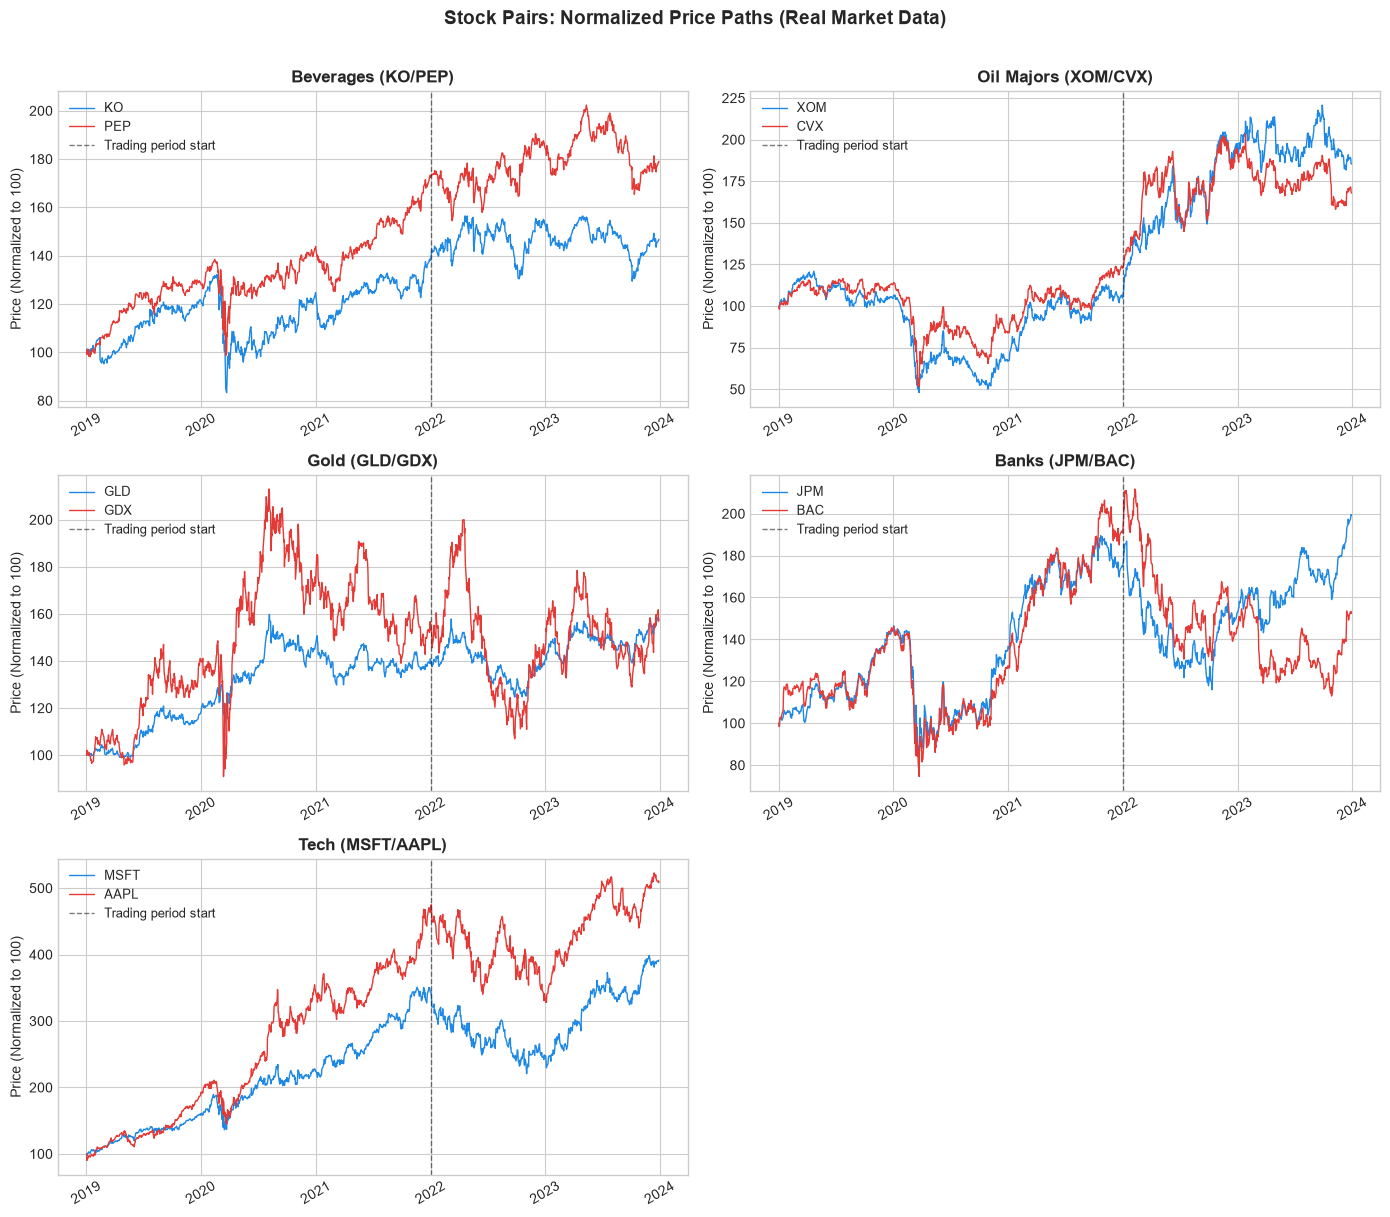

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes_flat = axes.flatten()

for i, (pair_name, df) in enumerate(pairs_data.items()):
    ax = axes_flat[i]
    cols = df.columns

    norm_1 = df[cols[0]] / df[cols[0]].iloc[0] * 100
    norm_2 = df[cols[1]] / df[cols[1]].iloc[0] * 100

    ax.plot(df.index, norm_1, color=COLORS['blue'], linewidth=1, label=cols[0])
    ax.plot(df.index, norm_2, color=COLORS['red'], linewidth=1, label=cols[1])
    ax.axvline(pd.Timestamp(TRADING_START), color=COLORS['dark'], linestyle='--',
               linewidth=1, alpha=0.6, label='Trading period start')
    ax.set_title(f"{pair_name}", fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.set_ylabel('Price (Normalized to 100)', fontsize=10)
    ax.tick_params(axis='x', rotation=30)

axes_flat[-1].set_visible(False)
fig.suptitle(f'Stock Pairs: Normalized Price Paths ({DATA_LABEL})',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

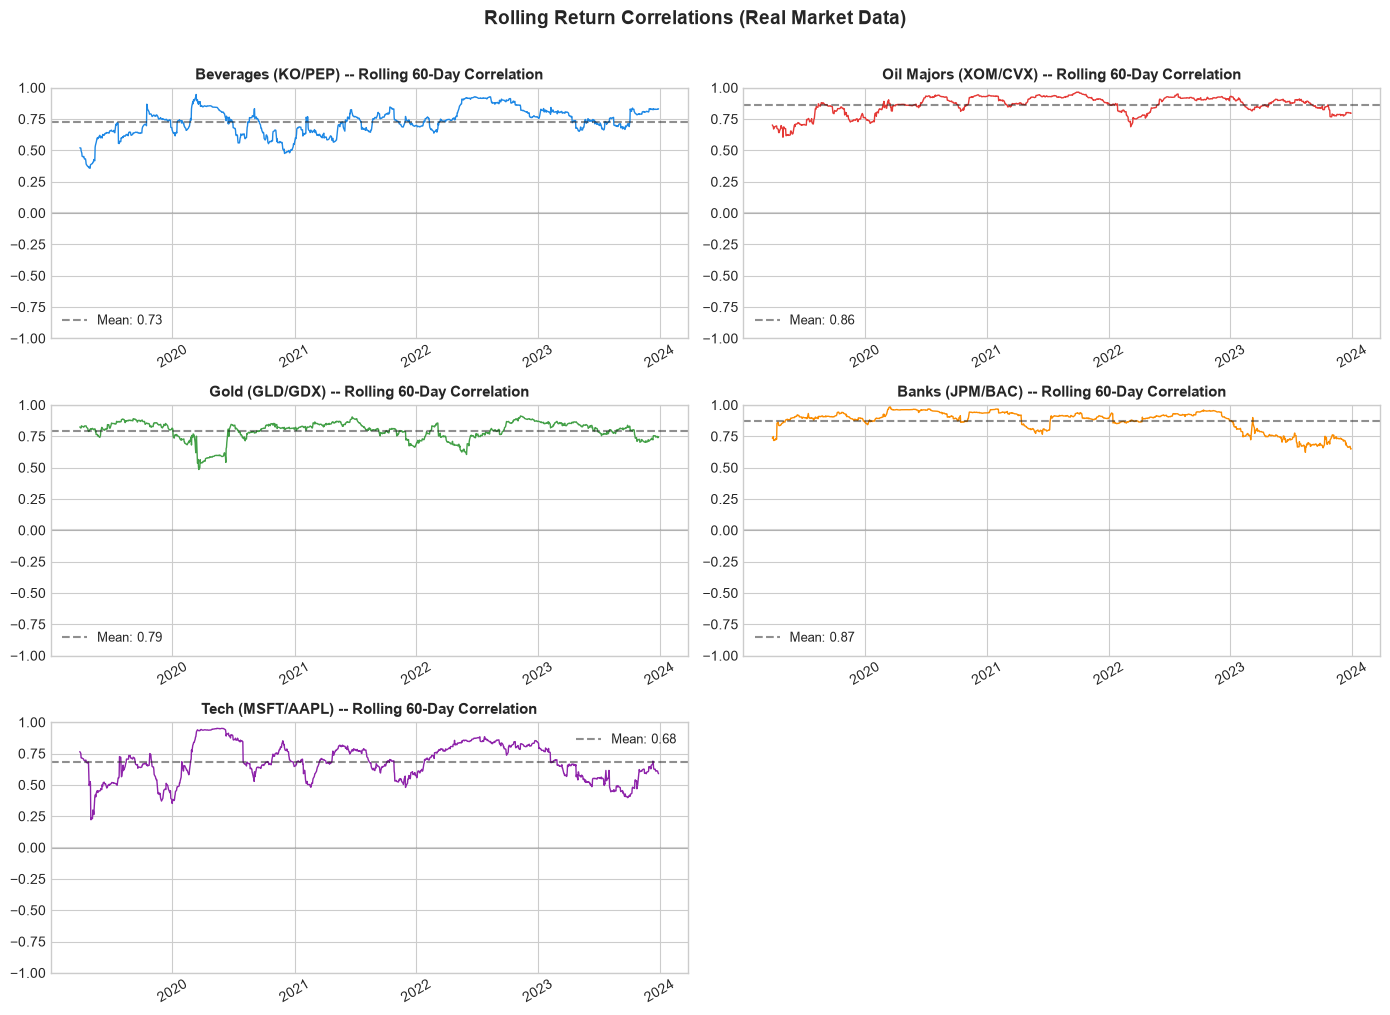

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes_flat = axes.flatten()

for i, (pair_name, df) in enumerate(pairs_data.items()):
    ax = axes_flat[i]
    cols = df.columns

    returns = df.pct_change().dropna()
    rolling_corr = returns[cols[0]].rolling(LOOKBACK).corr(returns[cols[1]])

    ax.plot(rolling_corr.index, rolling_corr, color=PAIR_COLORS[i], linewidth=1)
    ax.axhline(y=rolling_corr.mean(), color=COLORS['dark'], linestyle='--', alpha=0.5,
               label=f'Mean: {rolling_corr.mean():.2f}')
    ax.axhline(y=0, color=COLORS['grey'], linestyle='-', alpha=0.3)
    ax.set_title(f"{pair_name} -- Rolling {LOOKBACK}-Day Correlation", fontsize=11, fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.legend(fontsize=9)
    ax.tick_params(axis='x', rotation=30)

axes_flat[-1].set_visible(False)
fig.suptitle(f'Rolling Return Correlations ({DATA_LABEL})', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 3. Cointegration Testing

### Cointegration vs. Correlation

Two time series $X_t$ and $Y_t$ are **cointegrated** if both are $I(1)$
(integrated of order 1, i.e., non-stationary random walks), but there exists a
linear combination $Y_t - \beta X_t$ that is $I(0)$ (stationary).

> **Key insight**: Correlation measures co-movement of returns. Cointegration
> measures a long-run equilibrium relationship in levels. Two series can be
> highly correlated without being cointegrated, and vice versa.

All tests in this section use **only the formation period (2019–2021)**, so the
2022–2023 trading period remains a genuine out-of-sample test.

### 3.1 Engle-Granger Two-Step Test

The **Engle-Granger** procedure tests for cointegration between $Y_t$ and $X_t$:

**Step 1 -- Cointegrating Regression:**
$$Y_t = \alpha + \beta X_t + \epsilon_t$$

**Step 2 -- ADF Test on Residuals:**

Test whether $\hat{\epsilon}_t$ is stationary using the Augmented Dickey-Fuller regression:
$$\Delta \hat{\epsilon}_t = \gamma \hat{\epsilon}_{t-1} + \sum_{j=1}^{p} \delta_j \Delta \hat{\epsilon}_{t-j} + u_t$$

$H_0: \gamma = 0$ (no cointegration, residuals have a unit root)
$H_1: \gamma < 0$ (cointegration, residuals are stationary)

**Critical values** differ from standard ADF tables because the test is applied to
*estimated* residuals, which are mechanically made as stationary-looking as possible
by OLS. The correct reference is the Engle-Granger / MacKinnon distribution:

| Significance | 1%     | 5%     | 10%    |
|:------------|:-------|:-------|:-------|
| 2 variables | -3.90  | -3.34  | -3.04  |

Using ordinary ADF critical values (about -2.86 at 5%) would reject the null too
often. The implementation below therefore uses `statsmodels.tsa.stattools.coint`,
which applies the MacKinnon (2010) cointegration p-values and critical values.

In [6]:
def engle_granger_test(x, y, verbose=True):
    model = OLS(y, sm.add_constant(x)).fit()
    alpha, beta = model.params
    residuals = model.resid

    eg_stat, p_value, crit = coint(y, x, trend='c', autolag='aic')
    crit_values = {'1%': crit[0], '5%': crit[1], '10%': crit[2]}

    if verbose:
        print(f"  beta = {beta:.4f}, alpha = {alpha:.4f}")
        print(f"  EG stat = {eg_stat:.4f}, p-value = {p_value:.4f}")
        print(f"  EG critical values: 1%={crit_values['1%']:.3f}, "
              f"5%={crit_values['5%']:.3f}, 10%={crit_values['10%']:.3f}")
        print(f"  Cointegrated at 5%: {'YES' if p_value < SIGNIFICANCE else 'NO'}\n")

    return {
        'beta': beta, 'alpha': alpha,
        'eg_stat': eg_stat, 'p_value': p_value,
        'crit_values': crit_values, 'residuals': residuals
    }


print("=" * 60)
print(f"ENGLE-GRANGER TEST — FORMATION PERIOD ({DATA_LABEL})")
print("=" * 60)

eg_results = {}
for pair_name, df in formation_data.items():
    cols = df.columns
    print(f"\n{pair_name}:")
    eg_results[pair_name] = engle_granger_test(df[cols[0]].values, df[cols[1]].values)

summary_rows = []
for pair_name in pairs_data:
    r = eg_results[pair_name]
    cols = pairs_data[pair_name].columns
    summary_rows.append({
        'Pair': pair_name,
        'Tickers': f"{cols[0]}/{cols[1]}",
        'Beta': f"{r['beta']:.4f}",
        'EG Stat': f"{r['eg_stat']:.4f}",
        '5% Crit': f"{r['crit_values']['5%']:.3f}",
        'P-Value': f"{r['p_value']:.4f}",
        'Cointegrated (5%)': 'Yes' if r['p_value'] < SIGNIFICANCE else 'No'
    })

summary_df = pd.DataFrame(summary_rows)
print("=" * 60)
print(summary_df.to_string(index=False))

ENGLE-GRANGER TEST — FORMATION PERIOD (Real Market Data)

Beverages (KO/PEP):
  beta = 2.7961, alpha = -6.2747
  EG stat = -2.3759, p-value = 0.3363
  EG critical values: 1%=-3.911, 5%=-3.344, 10%=-3.050
  Cointegrated at 5%: NO


Oil Majors (XOM/CVX):
  beta = 1.1202, alpha = 29.0136
  EG stat = -3.2145, p-value = 0.0675
  EG critical values: 1%=-3.911, 5%=-3.344, 10%=-3.050
  Cointegrated at 5%: NO


Gold (GLD/GDX):
  beta = 0.2728, alpha = -13.5410
  EG stat = -2.8922, p-value = 0.1381
  EG critical values: 1%=-3.911, 5%=-3.344, 10%=-3.050
  Cointegrated at 5%: NO


Banks (JPM/BAC):
  beta = 0.2710, alpha = -1.2795
  EG stat = -1.5221, p-value = 0.7526
  EG critical values: 1%=-3.911, 5%=-3.344, 10%=-3.050
  Cointegrated at 5%: NO


Tech (MSFT/AAPL):
  beta = 0.5958, alpha = -20.0029
  EG stat = -2.0545, p-value = 0.5001
  EG critical values: 1%=-3.911, 5%=-3.344, 10%=-3.050
  Cointegrated at 5%: NO

                Pair   Tickers   Beta EG Stat 5% Crit P-Value Cointegrated (5%)
  B

### 3.2 Johansen Cointegration Test

The **Johansen test** is a multivariate generalization that can test for multiple
cointegrating relationships simultaneously. For a VAR(p) model:

$$\Delta \mathbf{Y}_t = \Pi \mathbf{Y}_{t-1} + \sum_{i=1}^{p-1} \Gamma_i \Delta \mathbf{Y}_{t-i} + \mathbf{u}_t$$

where $\Pi = \alpha \beta'$ and $\text{rank}(\Pi) = r$ gives the number of
cointegrating vectors.

**Trace statistic** tests $H_0: r \leq r_0$ vs $H_1: r > r_0$:
$$\lambda_{\text{trace}}(r_0) = -T \sum_{i=r_0+1}^{n} \ln(1 - \hat{\lambda}_i)$$

**Maximum eigenvalue statistic** tests $H_0: r = r_0$ vs $H_1: r = r_0 + 1$:
$$\lambda_{\max}(r_0, r_0+1) = -T \ln(1 - \hat{\lambda}_{r_0+1})$$

In [7]:
print("=" * 60)
print(f"JOHANSEN TEST — FORMATION PERIOD ({DATA_LABEL})")
print("=" * 60)

johansen_results = {}
for pair_name, df in formation_data.items():
    cols = df.columns
    jres = coint_johansen(df[[cols[0], cols[1]]].values, det_order=0, k_ar_diff=1)

    print(f"\n{pair_name}:")
    print(f"  Trace statistics:     {jres.lr1[0]:.2f}, {jres.lr1[1]:.2f}")
    print(f"  Trace 5% crit:        {jres.cvt[0, 1]:.2f}, {jres.cvt[1, 1]:.2f}")
    print(f"  Max-Eigen statistics: {jres.lr2[0]:.2f}, {jres.lr2[1]:.2f}")
    print(f"  Max-Eigen 5% crit:    {jres.cvm[0, 1]:.2f}, {jres.cvm[1, 1]:.2f}")
    print(f"  Reject r=0 (trace, 5%): {'YES' if jres.lr1[0] > jres.cvt[0, 1] else 'NO'}")

    johansen_results[pair_name] = jres

JOHANSEN TEST — FORMATION PERIOD (Real Market Data)

Beverages (KO/PEP):
  Trace statistics:     8.73, 0.65
  Trace 5% crit:        15.49, 3.84
  Max-Eigen statistics: 8.08, 0.65
  Max-Eigen 5% crit:    14.26, 3.84
  Reject r=0 (trace, 5%): NO

Oil Majors (XOM/CVX):
  Trace statistics:     9.45, 1.60
  Trace 5% crit:        15.49, 3.84
  Max-Eigen statistics: 7.84, 1.60
  Max-Eigen 5% crit:    14.26, 3.84
  Reject r=0 (trace, 5%): NO

Gold (GLD/GDX):
  Trace statistics:     13.72, 2.61
  Trace 5% crit:        15.49, 3.84
  Max-Eigen statistics: 11.11, 2.61
  Max-Eigen 5% crit:    14.26, 3.84
  Reject r=0 (trace, 5%): NO

Banks (JPM/BAC):
  Trace statistics:     6.47, 1.72
  Trace 5% crit:        15.49, 3.84
  Max-Eigen statistics: 4.75, 1.72
  Max-Eigen 5% crit:    14.26, 3.84
  Reject r=0 (trace, 5%): NO

Tech (MSFT/AAPL):
  Trace statistics:     5.69, 0.04
  Trace 5% crit:        15.49, 3.84
  Max-Eigen statistics: 5.65, 0.04
  Max-Eigen 5% crit:    14.26, 3.84
  Reject r=0 (trace, 5

### 3.3 Pair Selection

A pair is classified as cointegrated only if the **Engle-Granger test rejects at 5%**
in the formation period. The Engle-Granger result is the primary criterion because the
trading spread is built from the Engle-Granger hedge ratio; Johansen is reported as a
confirmation. Accepting a pair when *either* test rejects would inflate the false-positive
rate (two chances to reject).

If fewer than `MIN_PAIRS` pairs pass, the pairs with the lowest Engle-Granger p-values are
traded as **candidate pairs**. These are explicitly flagged: their out-of-sample results
test the strategy on pairs that did *not* show statistically significant cointegration.

In [8]:
coint_pairs = [p for p in pairs_data if eg_results[p]['p_value'] < SIGNIFICANCE]
johansen_confirmed = {p: johansen_results[p].lr1[0] > johansen_results[p].cvt[0, 1] for p in pairs_data}

print("Pairs cointegrated in the formation period (Engle-Granger, 5%):")
if coint_pairs:
    for p in coint_pairs:
        conf = 'confirmed' if johansen_confirmed[p] else 'not confirmed'
        print(f"  ✓ {p} (p={eg_results[p]['p_value']:.4f}, Johansen {conf})")
else:
    print("  none")

trade_pairs = list(coint_pairs)
candidate_pairs = []
if len(trade_pairs) < MIN_PAIRS:
    remaining = sorted([p for p in pairs_data if p not in trade_pairs],
                       key=lambda p: eg_results[p]['p_value'])
    candidate_pairs = remaining[:MIN_PAIRS - len(trade_pairs)]
    trade_pairs += candidate_pairs
    print(f"\n⚠️ Fewer than {MIN_PAIRS} pairs passed. Adding the lowest p-value candidates:")
    for p in candidate_pairs:
        print(f"  ? {p} (p={eg_results[p]['p_value']:.4f}) — NOT significant at 5%")

print("\nPairs traded out-of-sample:")
for p in trade_pairs:
    status = 'cointegrated' if p in coint_pairs else 'candidate only'
    print(f"  → {p} [{status}]")

excluded = [p for p in pairs_data if p not in trade_pairs]
print("\nPairs excluded:")
for p in excluded:
    print(f"  ✗ {p} (p={eg_results[p]['p_value']:.4f})")

Pairs cointegrated in the formation period (Engle-Granger, 5%):
  none

⚠️ Fewer than 3 pairs passed. Adding the lowest p-value candidates:
  ? Oil Majors (XOM/CVX) (p=0.0675) — NOT significant at 5%
  ? Gold (GLD/GDX) (p=0.1381) — NOT significant at 5%
  ? Beverages (KO/PEP) (p=0.3363) — NOT significant at 5%

Pairs traded out-of-sample:
  → Oil Majors (XOM/CVX) [candidate only]
  → Gold (GLD/GDX) [candidate only]
  → Beverages (KO/PEP) [candidate only]

Pairs excluded:
  ✗ Banks (JPM/BAC) (p=0.7526)
  ✗ Tech (MSFT/AAPL) (p=0.5001)


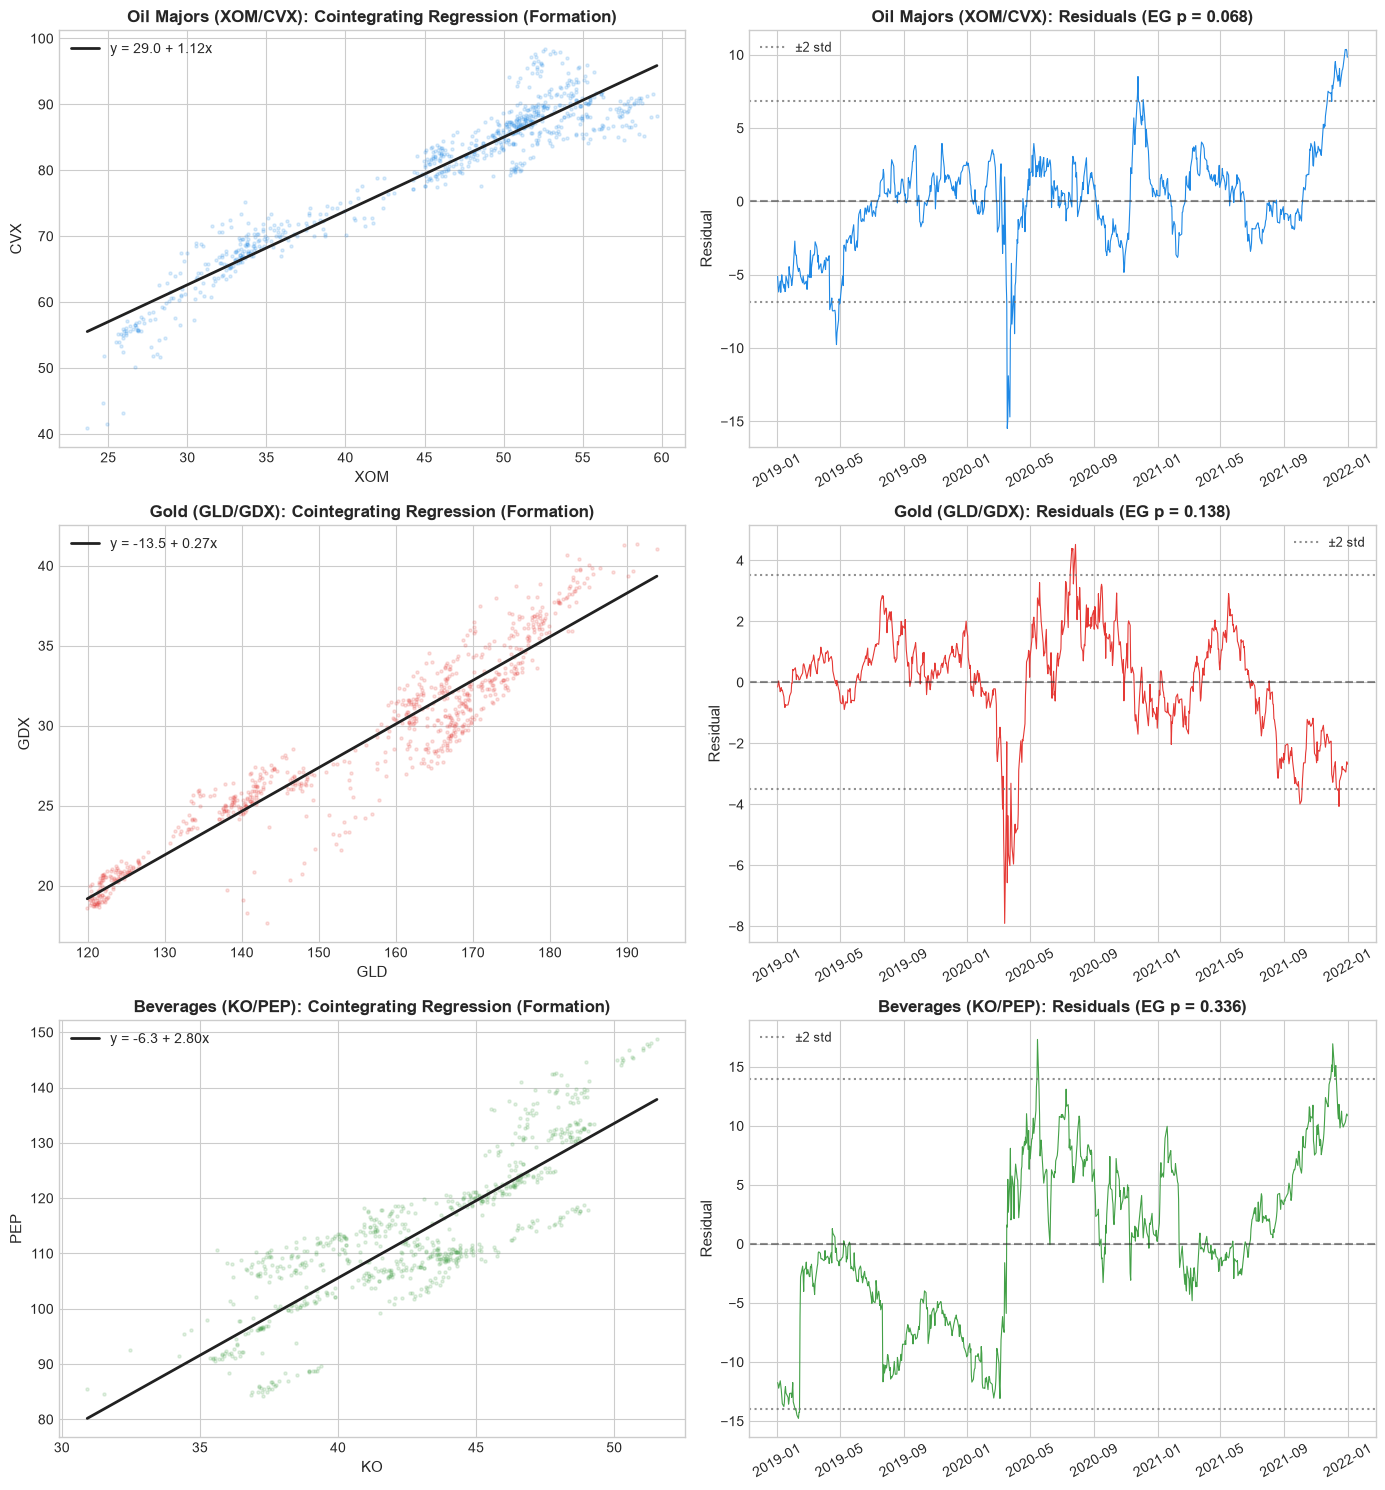

In [9]:
fig, axes = plt.subplots(len(trade_pairs), 2, figsize=(14, 5 * len(trade_pairs)))
if len(trade_pairs) == 1:
    axes = axes.reshape(1, 2)

for i, pair_name in enumerate(trade_pairs):
    df = formation_data[pair_name]
    cols = df.columns
    r = eg_results[pair_name]

    ax_scatter = axes[i, 0]
    ax_scatter.scatter(df[cols[0]], df[cols[1]], alpha=0.15, s=5, color=PAIR_COLORS[i])
    x_fit = np.linspace(df[cols[0]].min(), df[cols[0]].max(), 100)
    ax_scatter.plot(x_fit, r['alpha'] + r['beta'] * x_fit, color=COLORS['dark'], linewidth=2,
                    label=f'y = {r["alpha"]:.1f} + {r["beta"]:.2f}x')
    ax_scatter.set_xlabel(cols[0], fontsize=11)
    ax_scatter.set_ylabel(cols[1], fontsize=11)
    ax_scatter.set_title(f'{pair_name}: Cointegrating Regression (Formation)',
                         fontsize=12, fontweight='bold')
    ax_scatter.legend(fontsize=10)

    ax_resid = axes[i, 1]
    resid = pd.Series(r['residuals'], index=df.index)
    ax_resid.plot(resid.index, resid, color=PAIR_COLORS[i], linewidth=0.8)
    ax_resid.axhline(y=0, color=COLORS['dark'], linestyle='--', alpha=0.5)
    ax_resid.axhline(y=resid.std() * 2, color=COLORS['grey'], linestyle=':', alpha=0.8, label='±2 std')
    ax_resid.axhline(y=-resid.std() * 2, color=COLORS['grey'], linestyle=':', alpha=0.8)
    ax_resid.set_title(f'{pair_name}: Residuals (EG p = {r["p_value"]:.3f})',
                       fontsize=12, fontweight='bold')
    ax_resid.set_ylabel('Residual', fontsize=11)
    ax_resid.legend(fontsize=9)
    ax_resid.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 4. Spread Modeling

### The Spread and Ornstein-Uhlenbeck Process

For a pair with $Y_t = \alpha + \beta X_t + \epsilon_t$, the **spread** is:
$$S_t = Y_t - \beta X_t - \alpha$$

$\alpha$ and $\beta$ are fixed at their formation-period estimates, and the same
values are applied to the trading period. The spread over the trading period is
therefore what a trader would actually have observed with no hindsight.

If the pair is truly cointegrated, $S_t$ follows a mean-reverting process well
approximated by the **Ornstein-Uhlenbeck (OU)** process:

$$dS_t = \theta(\mu - S_t)\,dt + \sigma\,dW_t$$

where:
- $\theta > 0$: speed of mean reversion (larger = faster reversion)
- $\mu$: long-run equilibrium level of the spread
- $\sigma$: volatility of the spread
- $W_t$: standard Brownian motion

### Discrete-Time Estimation

The exact discretization of the OU process at a daily step is an AR(1):
$$S_t = \phi S_{t-1} + (1-\phi)\mu + \varepsilon_t, \qquad \phi = e^{-\theta}$$

Rewriting for OLS: $\Delta S_t = a + b \cdot S_{t-1} + e_t$ with $b = \phi - 1$ and
$a = (1-\phi)\mu$. Therefore

$$\theta = -\ln(1 + b), \qquad \mu = -\frac{a}{b}, \qquad
\sigma = \sigma_e \sqrt{\frac{2\theta}{1-\phi^2}}$$

and the **half-life** of mean reversion (in trading days) is
$$\tau_{1/2} = \frac{\ln 2}{\theta} = -\frac{\ln 2}{\ln(1 + b)}$$

The common shortcut $-\ln 2 / b$ is only a first-order approximation and understates
the half-life when reversion is fast.

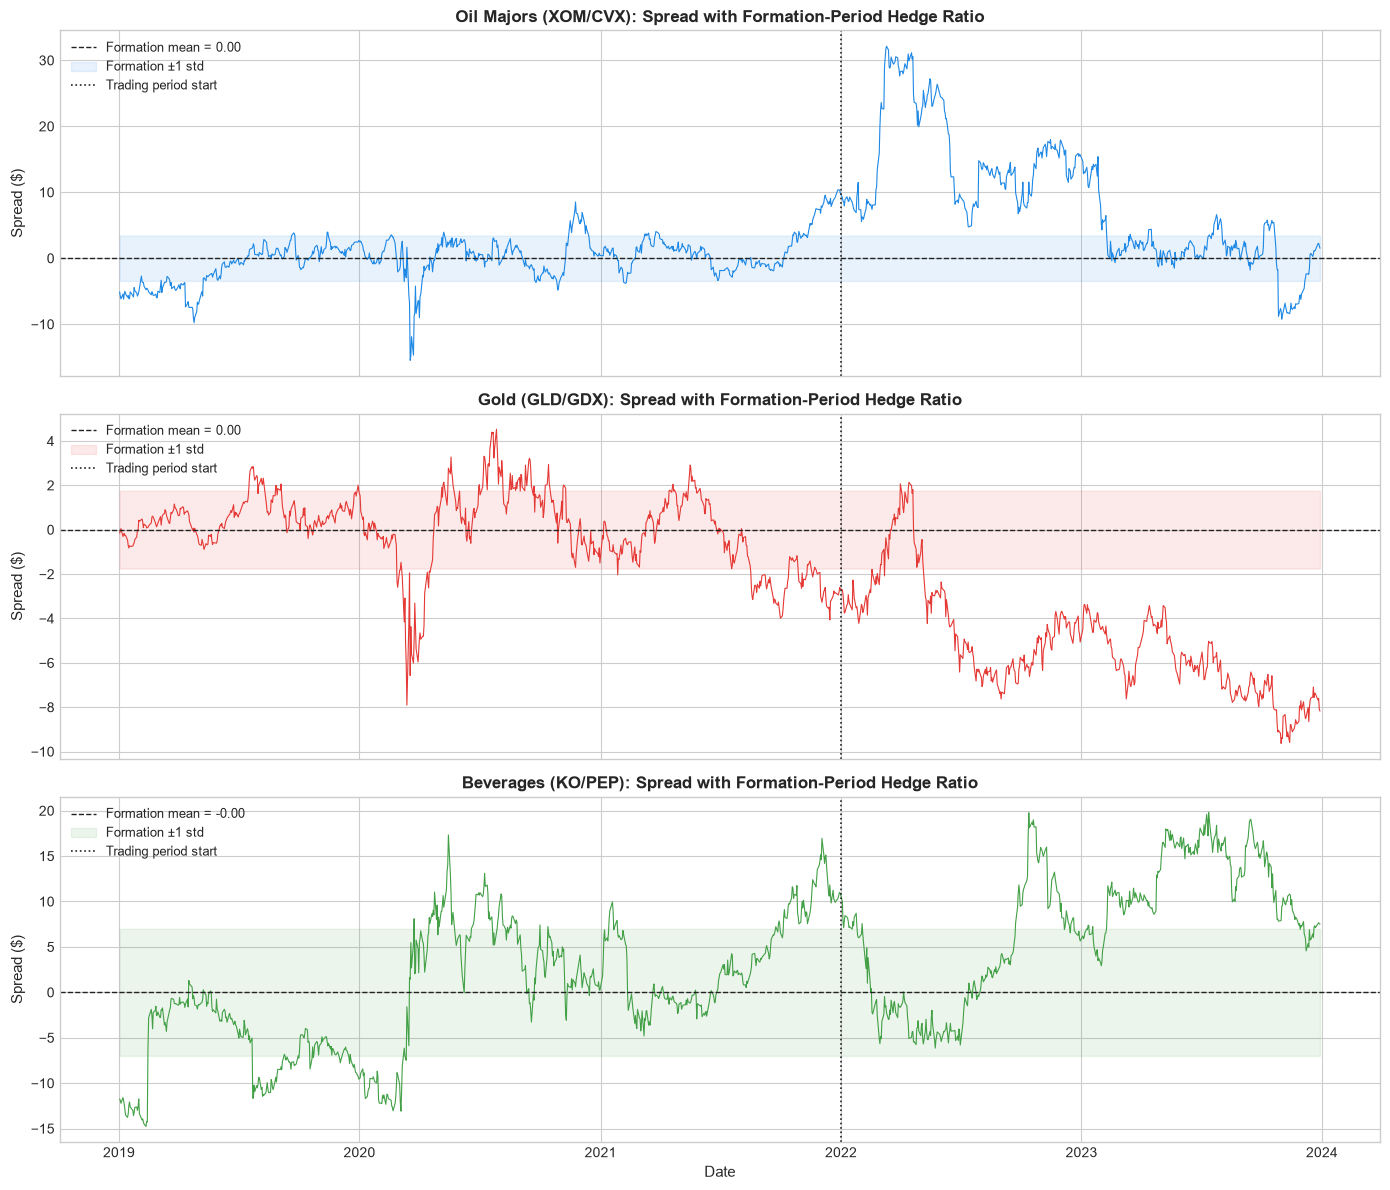

In [10]:
spreads = {}
gross_exposure = {}

for pair_name in trade_pairs:
    df = pairs_data[pair_name]
    cols = df.columns
    r = eg_results[pair_name]
    spreads[pair_name] = df[cols[1]] - r['beta'] * df[cols[0]] - r['alpha']
    gross_exposure[pair_name] = df[cols[1]] + abs(r['beta']) * df[cols[0]]

fig, axes = plt.subplots(len(trade_pairs), 1, figsize=(14, 4 * len(trade_pairs)), sharex=True)
if len(trade_pairs) == 1:
    axes = [axes]

for i, pair_name in enumerate(trade_pairs):
    ax = axes[i]
    s = spreads[pair_name]
    s_form = s.loc[:FORMATION_END]
    ax.plot(s.index, s, color=PAIR_COLORS[i], linewidth=0.8)
    ax.axhline(y=s_form.mean(), color=COLORS['dark'], linestyle='--', linewidth=1,
               label=f'Formation mean = {s_form.mean():.2f}')
    ax.fill_between(s.index, s_form.mean() - s_form.std(), s_form.mean() + s_form.std(),
                    alpha=0.1, color=PAIR_COLORS[i], label='Formation ±1 std')
    ax.axvline(pd.Timestamp(TRADING_START), color=COLORS['dark'], linestyle=':',
               linewidth=1.2, label='Trading period start')
    ax.set_title(f'{pair_name}: Spread with Formation-Period Hedge Ratio',
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Spread ($)', fontsize=11)
    ax.legend(fontsize=9, loc='upper left')

plt.xlabel('Date', fontsize=11)
plt.tight_layout()
plt.show()

In [11]:
def estimate_ou_parameters(spread):
    s = np.asarray(spread, dtype=float)
    delta_s = np.diff(s)
    s_lag = s[:-1]

    model = OLS(delta_s, sm.add_constant(s_lag)).fit()
    a, b = model.params
    resid_std = np.std(model.resid, ddof=2)

    if -1 < b < 0:
        phi = 1 + b
        theta = -np.log(phi)
        mu = -a / b
        sigma = resid_std * np.sqrt(2 * theta / (1 - phi**2))
        half_life = np.log(2) / theta
    else:
        phi, theta, mu, sigma, half_life = 1 + b, 0.0, np.nan, np.nan, np.inf

    return {
        'theta': theta, 'mu': mu, 'sigma': sigma, 'phi': phi,
        'half_life': half_life, 'a': a, 'b': b,
        'resid_std': resid_std
    }


print("=" * 90)
print(f"ORNSTEIN-UHLENBECK PARAMETERS — FORMATION PERIOD ({DATA_LABEL})")
print("=" * 90)
print(f"{'Pair':<26} {'Theta (1/day)':>14} {'Mu':>8} {'Sigma (daily)':>14} "
      f"{'Sigma (ann.)':>13} {'Half-Life (days)':>17}")
print("-" * 90)

ou_params = {}
for pair_name in trade_pairs:
    params = estimate_ou_parameters(spreads[pair_name].loc[:FORMATION_END])
    ou_params[pair_name] = params
    print(f"{pair_name:<26} {params['theta']:>14.4f} {params['mu']:>8.3f} "
          f"{params['sigma']:>14.4f} {params['sigma'] * np.sqrt(252):>13.4f} "
          f"{params['half_life']:>17.1f}")

ORNSTEIN-UHLENBECK PARAMETERS — FORMATION PERIOD (Real Market Data)
Pair                        Theta (1/day)       Mu  Sigma (daily)  Sigma (ann.)  Half-Life (days)
------------------------------------------------------------------------------------------
Oil Majors (XOM/CVX)               0.0344    0.571         0.9513       15.1020              20.1
Gold (GLD/GDX)                     0.0376   -0.087         0.4909        7.7926              18.4
Beverages (KO/PEP)                 0.0150    1.992         1.1992       19.0366              46.2


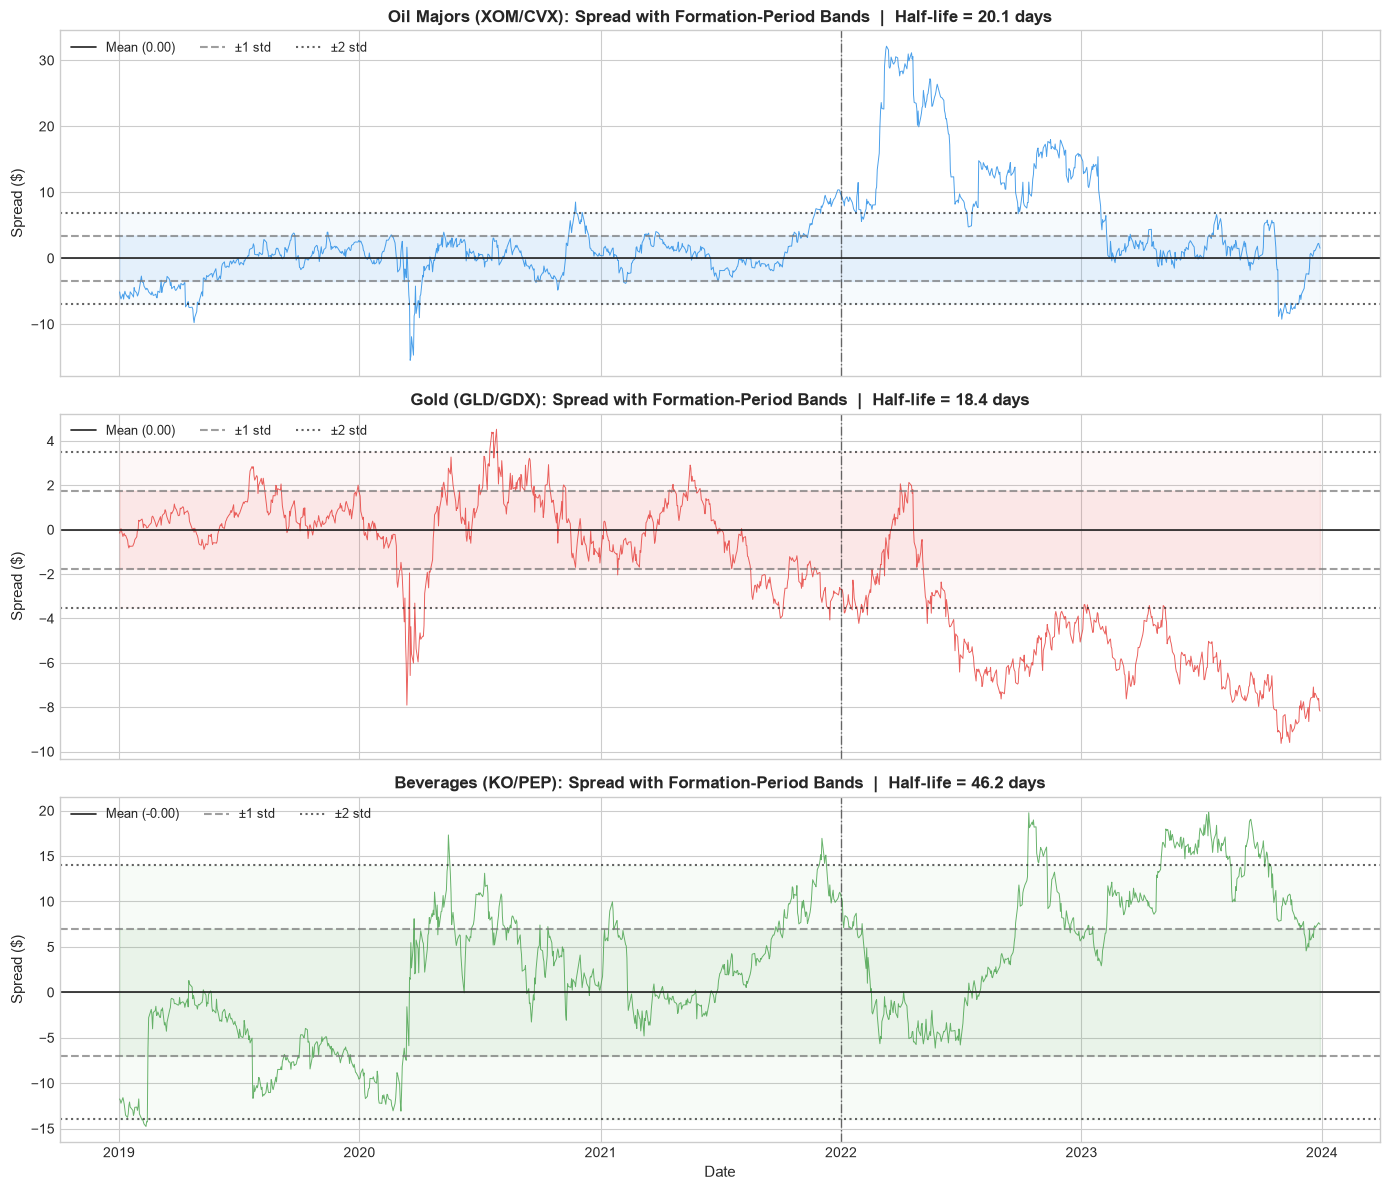

In [12]:
fig, axes = plt.subplots(len(trade_pairs), 1, figsize=(14, 4 * len(trade_pairs)), sharex=True)
if len(trade_pairs) == 1:
    axes = [axes]

for i, pair_name in enumerate(trade_pairs):
    ax = axes[i]
    s = spreads[pair_name]
    s_form = s.loc[:FORMATION_END]
    mu = s_form.mean()
    sd = s_form.std()
    hl = ou_params[pair_name]['half_life']

    ax.plot(s.index, s, color=PAIR_COLORS[i], linewidth=0.7, alpha=0.8)
    ax.axhline(y=mu, color=COLORS['dark'], linestyle='-', linewidth=1.2, label=f'Mean ({mu:.2f})')
    ax.axhline(y=mu + sd, color=COLORS['grey'], linestyle='--', alpha=0.7)
    ax.axhline(y=mu - sd, color=COLORS['grey'], linestyle='--', alpha=0.7, label='±1 std')
    ax.axhline(y=mu + 2*sd, color=COLORS['dark'], linestyle=':', alpha=0.7)
    ax.axhline(y=mu - 2*sd, color=COLORS['dark'], linestyle=':', alpha=0.7, label='±2 std')
    ax.fill_between(s.index, mu - sd, mu + sd, alpha=0.08, color=PAIR_COLORS[i])
    ax.fill_between(s.index, mu - 2*sd, mu + 2*sd, alpha=0.04, color=PAIR_COLORS[i])
    ax.axvline(pd.Timestamp(TRADING_START), color=COLORS['dark'], linestyle='-.',
               linewidth=1, alpha=0.6)

    ax.set_title(f'{pair_name}: Spread with Formation-Period Bands  |  Half-life = {hl:.1f} days',
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Spread ($)', fontsize=11)
    ax.legend(loc='upper left', fontsize=9, ncol=3)

plt.xlabel('Date', fontsize=11)
plt.tight_layout()
plt.show()

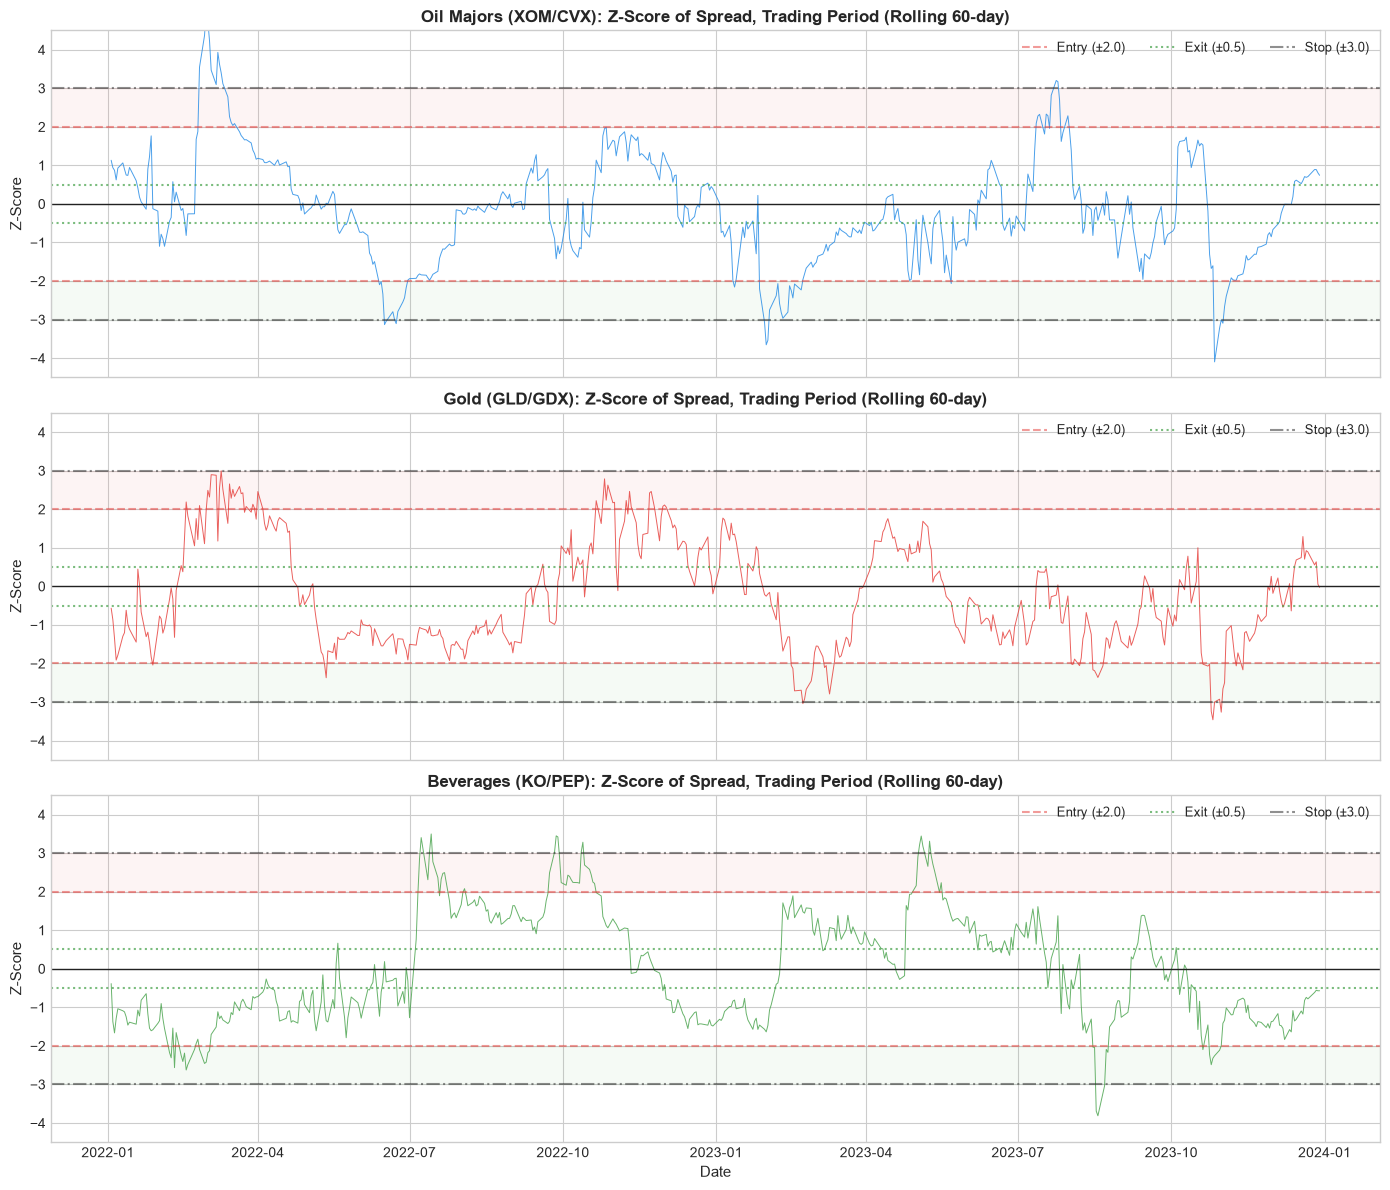

In [13]:
def rolling_zscore(spread, lookback=LOOKBACK):
    rolling_mean = spread.rolling(lookback).mean()
    rolling_std = spread.rolling(lookback).std()
    return (spread - rolling_mean) / rolling_std


z_scores = {pair_name: rolling_zscore(spreads[pair_name]) for pair_name in trade_pairs}

fig, axes = plt.subplots(len(trade_pairs), 1, figsize=(14, 4 * len(trade_pairs)), sharex=True)
if len(trade_pairs) == 1:
    axes = [axes]

for i, pair_name in enumerate(trade_pairs):
    ax = axes[i]
    z = z_scores[pair_name].loc[TRADING_START:]

    ax.plot(z.index, z, color=PAIR_COLORS[i], linewidth=0.7, alpha=0.8)
    ax.axhline(y=0, color=COLORS['dark'], linestyle='-', linewidth=1)
    ax.axhline(y=Z_ENTRY, color=COLORS['red'], linestyle='--', alpha=0.5, label=f'Entry (±{Z_ENTRY})')
    ax.axhline(y=-Z_ENTRY, color=COLORS['red'], linestyle='--', alpha=0.5)
    ax.axhline(y=Z_EXIT, color=COLORS['green'], linestyle=':', alpha=0.7, label=f'Exit (±{Z_EXIT})')
    ax.axhline(y=-Z_EXIT, color=COLORS['green'], linestyle=':', alpha=0.7)
    ax.axhline(y=Z_STOP, color=COLORS['dark'], linestyle='-.', alpha=0.5, label=f'Stop (±{Z_STOP})')
    ax.axhline(y=-Z_STOP, color=COLORS['dark'], linestyle='-.', alpha=0.5)
    ax.axhspan(Z_ENTRY, Z_STOP, alpha=0.05, color=COLORS['red'])
    ax.axhspan(-Z_STOP, -Z_ENTRY, alpha=0.05, color=COLORS['green'])

    ax.set_title(f'{pair_name}: Z-Score of Spread, Trading Period (Rolling {LOOKBACK}-day)',
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Z-Score', fontsize=11)
    ax.set_ylim(-4.5, 4.5)
    ax.legend(loc='upper right', fontsize=9, ncol=3)

plt.xlabel('Date', fontsize=11)
plt.tight_layout()
plt.show()

## 5. Pairs Trading Strategy (Out-of-Sample)

### Z-Score-Based Trading Rules

| Condition | Action |
|:----------|:-------|
| $z_t < -z_{\text{entry}}$ and flat | Go **long** the spread (buy 1 share of Y, sell $\beta$ shares of X) |
| $z_t > +z_{\text{entry}}$ and flat | Go **short** the spread (sell 1 share of Y, buy $\beta$ shares of X) |
| $\|z_t\| < z_{\text{exit}}$ | **Close** position |
| $\|z_t\| > z_{\text{stop}}$ | **Stop-loss**: close position |
| After a stop-loss | **No re-entry** until $\|z_t\|$ falls back below $z_{\text{entry}}$ |

With the parameters in this notebook: entry at $|z| > 2.0$, exit at $|z| < 0.5$,
stop-loss at $|z| > 3.0$. The re-entry lock prevents the strategy from immediately
re-opening a trade that was just stopped out while the spread is still extended.

**Position**: $+1$ = long spread, $-1$ = short spread, $0$ = flat. The signal at the
close of day $t$ is executed at that close and earns the return of day $t+1$.

### Return Definition

One unit of the spread is long 1 share of $Y$ and short $\beta$ shares of $X$, so its
dollar P&L is $\Delta S_t = \Delta Y_t - \beta \Delta X_t$. Returns are measured on the
**gross exposure** $G_{t-1} = Y_{t-1} + |\beta| X_{t-1}$:

$$r_t = \text{position}_{t-1}\,\frac{\Delta S_t}{G_{t-1}} \;-\; c\,|\text{position}_t - \text{position}_{t-1}|$$

where $c$ = `TRANSACTION_COST` (5 bps of gross notional per position change, i.e.
10 bps per round trip), covering commissions, bid-ask spread and slippage. Short-borrow
fees are not modelled.

All performance numbers use **only the trading period** (2022–2023). The rolling z-score
window is seeded with the final 60 days of the formation period, which are known before
trading begins.

In [14]:
def generate_signals(z_score, z_entry=Z_ENTRY, z_exit=Z_EXIT, z_stop=Z_STOP):
    z_values = np.asarray(z_score, dtype=float)
    positions = np.zeros(len(z_values))
    pos = 0.0
    locked = False

    for t, z in enumerate(z_values):
        if np.isnan(z):
            positions[t] = pos
            continue

        if locked and abs(z) < z_entry:
            locked = False

        if pos != 0.0 and abs(z) > z_stop:
            pos = 0.0
            locked = True
        elif pos != 0.0 and abs(z) < z_exit:
            pos = 0.0
        elif pos == 0.0 and not locked and z_entry < abs(z) <= z_stop:
            pos = 1.0 if z < 0 else -1.0

        positions[t] = pos

    return pd.Series(positions, index=getattr(z_score, 'index', None))


def strategy_returns_from(spread, gross, positions, cost=TRANSACTION_COST):
    held = positions.shift(1).fillna(0.0)
    gross_ret = held * spread.diff() / gross.shift(1)
    turnover = positions.diff().abs().fillna(positions.abs())
    return (gross_ret.fillna(0.0) - cost * turnover), gross_ret.fillna(0.0)


positions = {}
strategy_returns = {}
strategy_returns_gross = {}

for pair_name in trade_pairs:
    z_trade = z_scores[pair_name].loc[TRADING_START:]
    pos = generate_signals(z_trade)
    net, gross = strategy_returns_from(spreads[pair_name].loc[TRADING_START:],
                                       gross_exposure[pair_name].loc[TRADING_START:], pos)
    positions[pair_name] = pos
    strategy_returns[pair_name] = net
    strategy_returns_gross[pair_name] = gross

    n_long = (pos == 1).sum()
    n_short = (pos == -1).sum()
    n_flat = (pos == 0).sum()
    print(f"{pair_name}: Long={n_long} days, Short={n_short} days, Flat={n_flat} days, "
          f"Invested={(n_long + n_short) / len(pos):.1%}")

Oil Majors (XOM/CVX): Long=31 days, Short=38 days, Flat=432 days, Invested=13.8%
Gold (GLD/GDX): Long=152 days, Short=79 days, Flat=270 days, Invested=46.1%
Beverages (KO/PEP): Long=92 days, Short=65 days, Flat=344 days, Invested=31.3%


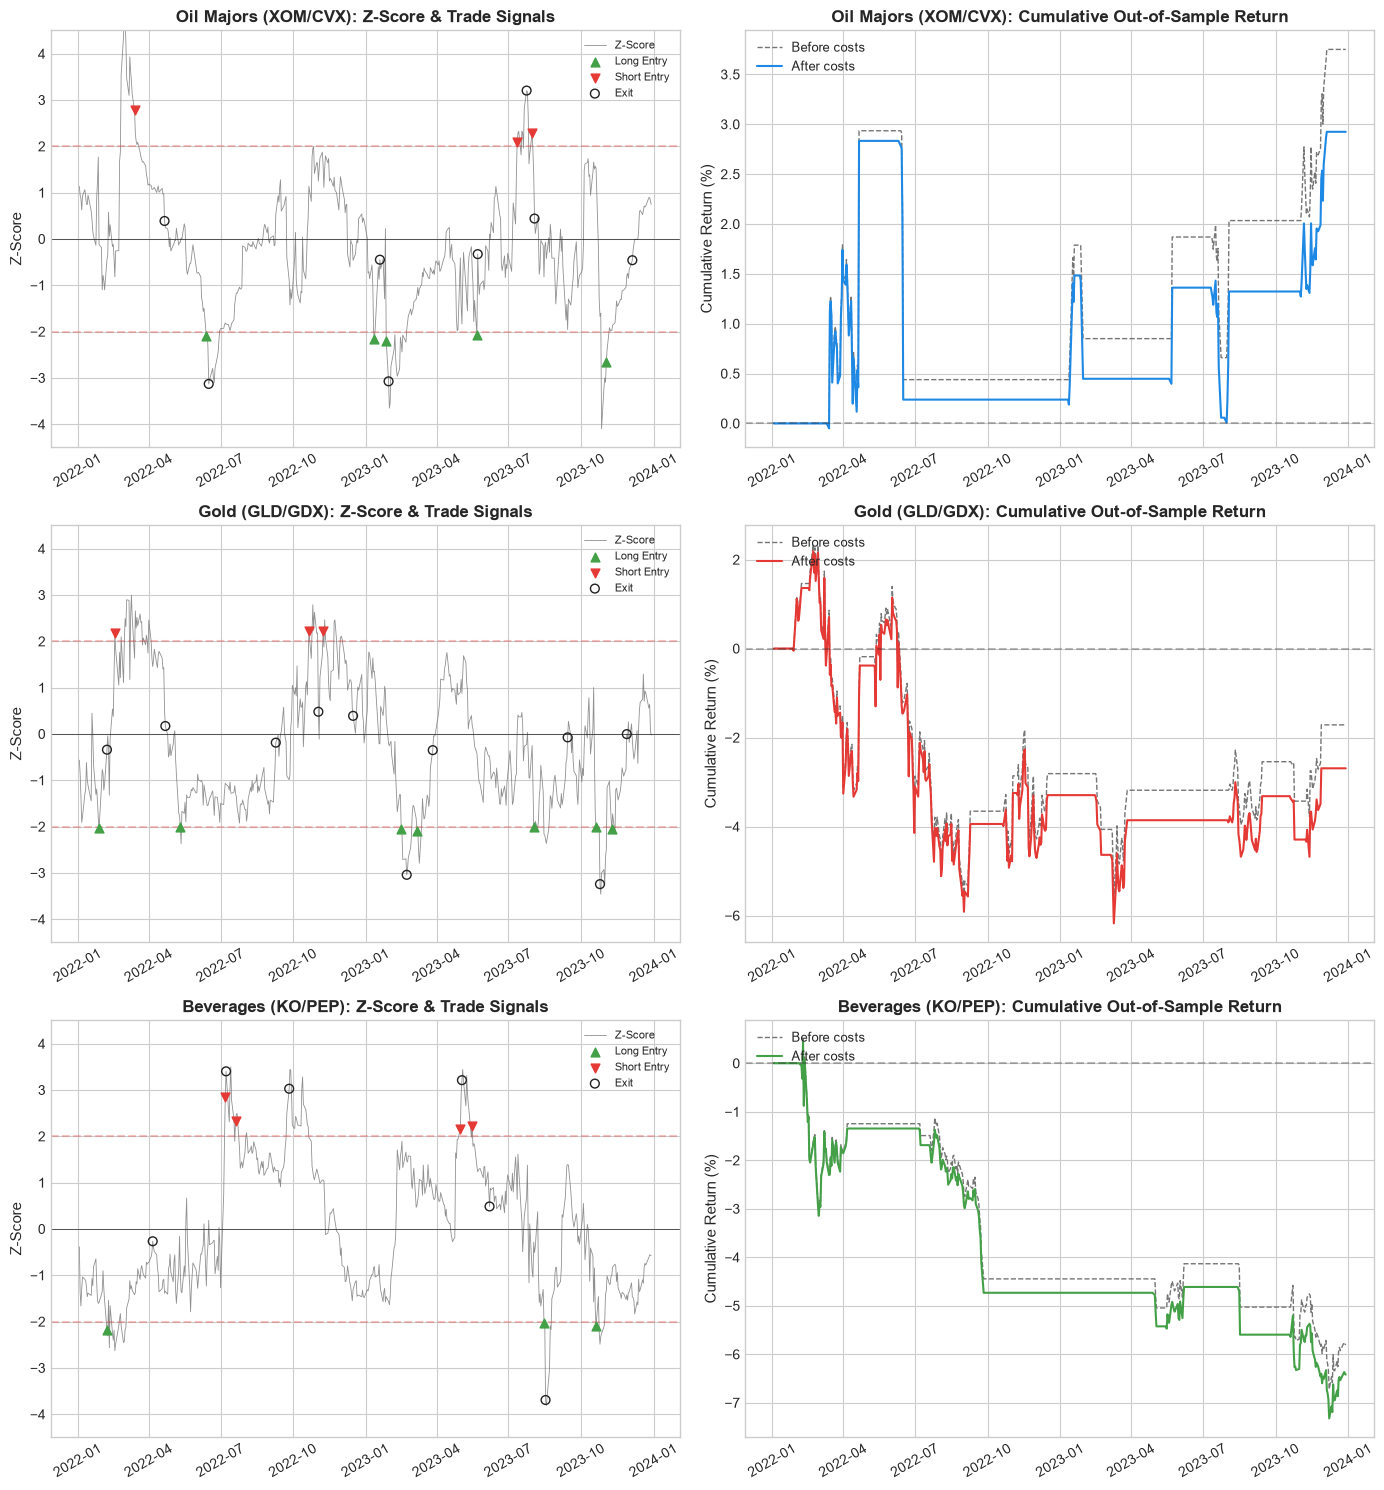

In [15]:
fig, axes = plt.subplots(len(trade_pairs), 2, figsize=(14, 5 * len(trade_pairs)))
if len(trade_pairs) == 1:
    axes = axes.reshape(1, 2)

for i, pair_name in enumerate(trade_pairs):
    z = z_scores[pair_name].loc[TRADING_START:]
    pos = positions[pair_name]
    net = strategy_returns[pair_name]
    gross = strategy_returns_gross[pair_name]

    ax1 = axes[i, 0]
    ax1.plot(z.index, z, color=COLORS['grey'], linewidth=0.6, alpha=0.8, label='Z-Score')
    ax1.axhline(y=0, color=COLORS['dark'], linestyle='-', linewidth=0.5)
    ax1.axhline(y=Z_ENTRY, color=COLORS['red'], linestyle='--', alpha=0.3)
    ax1.axhline(y=-Z_ENTRY, color=COLORS['red'], linestyle='--', alpha=0.3)

    prev = pos.shift(1).fillna(0)
    entries_long = pos[(pos == 1) & (prev == 0)].index
    entries_short = pos[(pos == -1) & (prev == 0)].index
    exits = pos[(pos == 0) & (prev != 0)].index

    ax1.scatter(entries_long, z.reindex(entries_long), marker='^', color=COLORS['green'],
                s=40, zorder=5, label='Long Entry')
    ax1.scatter(entries_short, z.reindex(entries_short), marker='v', color=COLORS['red'],
                s=40, zorder=5, label='Short Entry')
    ax1.scatter(exits, z.reindex(exits), marker='o', facecolors='none',
                edgecolors=COLORS['dark'], s=40, zorder=5, label='Exit')

    ax1.set_title(f'{pair_name}: Z-Score & Trade Signals', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Z-Score', fontsize=11)
    ax1.legend(fontsize=8, loc='upper right')
    ax1.set_ylim(-4.5, 4.5)
    ax1.tick_params(axis='x', rotation=30)

    ax2 = axes[i, 1]
    equity_net = (1 + net).cumprod() - 1
    equity_gross = (1 + gross).cumprod() - 1
    ax2.plot(equity_gross.index, equity_gross * 100, color=COLORS['grey'], linewidth=1,
             linestyle='--', label='Before costs')
    ax2.plot(equity_net.index, equity_net * 100, color=PAIR_COLORS[i], linewidth=1.5,
             label='After costs')
    ax2.axhline(y=0, color=COLORS['dark'], linestyle='--', alpha=0.3)
    ax2.set_title(f'{pair_name}: Cumulative Out-of-Sample Return', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Cumulative Return (%)', fontsize=11)
    ax2.legend(fontsize=9, loc='upper left')
    ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [16]:
def extract_trades(returns, positions):
    held = positions.shift(1).fillna(0.0)
    trade_id = ((positions != 0) & (held == 0)).cumsum()
    active = (positions != 0) | (held != 0)

    trade_pnl = (1 + returns[active]).groupby(trade_id[active]).prod() - 1
    trade_duration = held[held != 0].groupby(trade_id[held != 0]).count()
    return trade_pnl, trade_duration.reindex(trade_pnl.index, fill_value=0)


def compute_performance_metrics(returns, positions):
    r = returns.dropna()
    n = len(r)
    equity = (1 + r).cumprod()
    total_return = equity.iloc[-1] - 1
    ann_return = (1 + total_return) ** (252 / n) - 1
    ann_vol = r.std() * np.sqrt(252)
    downside_dev = np.sqrt(np.mean(np.minimum(r, 0) ** 2)) * np.sqrt(252)
    drawdown = equity / equity.cummax() - 1

    trade_pnl, trade_duration = extract_trades(r, positions)
    n_trades = len(trade_pnl)

    metrics = {}
    metrics['Total Return'] = f"{total_return:.2%}"
    metrics['Ann. Return (CAGR)'] = f"{ann_return:.2%}"
    metrics['Ann. Volatility'] = f"{ann_vol:.2%}"
    metrics['Sharpe Ratio'] = f"{r.mean() / r.std() * np.sqrt(252):.3f}" if r.std() > 0 else 'N/A'
    metrics['Sortino Ratio'] = f"{r.mean() * 252 / downside_dev:.3f}" if downside_dev > 0 else 'N/A'
    metrics['Max Drawdown'] = f"{drawdown.min():.2%}"
    metrics['Number of Trades'] = f"{n_trades}"
    if n_trades > 0:
        wins = trade_pnl[trade_pnl > 0]
        losses = trade_pnl[trade_pnl < 0]
        metrics['Win Rate (per trade)'] = f"{len(wins) / n_trades:.2%}"
        metrics['Avg Trade Return'] = f"{trade_pnl.mean():.2%}"
        metrics['Profit Factor'] = f"{wins.sum() / abs(losses.sum()):.3f}" if len(losses) > 0 else 'N/A'
        metrics['Avg Trade Duration'] = f"{trade_duration.mean():.1f} days"
        metrics['Median Trade Duration'] = f"{trade_duration.median():.1f} days"
    else:
        for k in ['Win Rate (per trade)', 'Avg Trade Return', 'Profit Factor',
                  'Avg Trade Duration', 'Median Trade Duration']:
            metrics[k] = 'N/A'
    return metrics


print("=" * 75)
print(f"OUT-OF-SAMPLE PERFORMANCE, NET OF COSTS ({TRADING_START} onward, {DATA_LABEL})")
print("=" * 75)

all_metrics = {}
for pair_name in trade_pairs:
    metrics = compute_performance_metrics(strategy_returns[pair_name], positions[pair_name])
    all_metrics[pair_name] = metrics
    flag = '' if pair_name in coint_pairs else '  [candidate — not cointegrated at 5%]'
    print(f"\n--- {pair_name}{flag} ---")
    for k, v in metrics.items():
        print(f"  {k:<25s} {v}")

print("\n" + "=" * 75)
print(pd.DataFrame(all_metrics).to_string())

OUT-OF-SAMPLE PERFORMANCE, NET OF COSTS (2022-01-01 onward, Real Market Data)

--- Oil Majors (XOM/CVX)  [candidate — not cointegrated at 5%] ---
  Total Return              2.92%
  Ann. Return (CAGR)        1.46%
  Ann. Volatility           3.20%
  Sharpe Ratio              0.469
  Sortino Ratio             0.775
  Max Drawdown              -2.75%
  Number of Trades          8
  Win Rate (per trade)      62.50%
  Avg Trade Return          0.37%
  Profit Factor             1.621
  Avg Trade Duration        8.6 days
  Median Trade Duration     3.5 days

--- Gold (GLD/GDX)  [candidate — not cointegrated at 5%] ---
  Total Return              -2.69%
  Ann. Return (CAGR)        -1.36%
  Ann. Volatility           5.96%
  Sharpe Ratio              -0.201
  Sortino Ratio             -0.286
  Max Drawdown              -8.19%
  Number of Trades          10
  Win Rate (per trade)      50.00%
  Avg Trade Return          -0.26%
  Profit Factor             0.664
  Avg Trade Duration        23.1 day

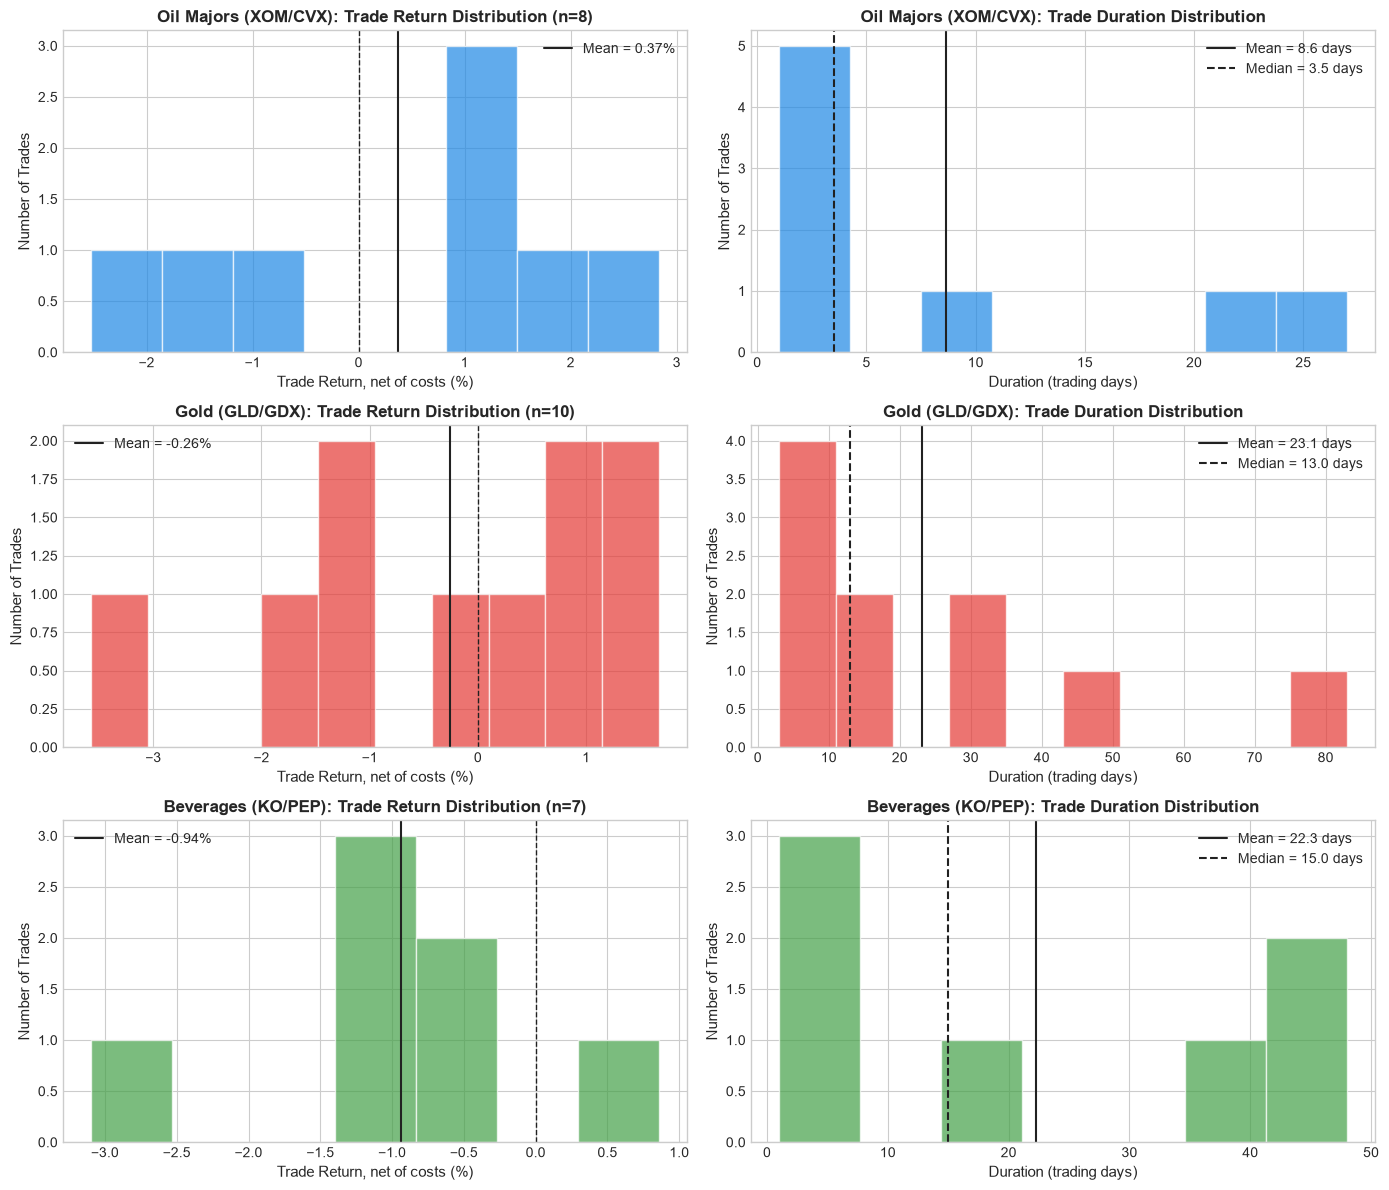

In [17]:
fig, axes = plt.subplots(len(trade_pairs), 2, figsize=(14, 4 * len(trade_pairs)))
if len(trade_pairs) == 1:
    axes = axes.reshape(1, 2)

for i, pair_name in enumerate(trade_pairs):
    trade_pnl, trade_dur = extract_trades(strategy_returns[pair_name], positions[pair_name])

    ax1 = axes[i, 0]
    if len(trade_pnl) > 0:
        ax1.hist(trade_pnl * 100, bins=min(30, max(5, len(trade_pnl))), color=PAIR_COLORS[i],
                 alpha=0.7, edgecolor='white')
        ax1.axvline(x=0, color=COLORS['dark'], linestyle='--', linewidth=1)
        ax1.axvline(x=trade_pnl.mean() * 100, color=COLORS['dark'], linestyle='-', linewidth=1.5,
                    label=f'Mean = {trade_pnl.mean():.2%}')
        ax1.legend(fontsize=10)
    ax1.set_title(f'{pair_name}: Trade Return Distribution (n={len(trade_pnl)})',
                  fontsize=12, fontweight='bold')
    ax1.set_xlabel('Trade Return, net of costs (%)', fontsize=11)
    ax1.set_ylabel('Number of Trades', fontsize=11)

    ax2 = axes[i, 1]
    if len(trade_dur) > 0:
        ax2.hist(trade_dur, bins=min(30, max(5, len(trade_dur))), color=PAIR_COLORS[i],
                 alpha=0.7, edgecolor='white')
        ax2.axvline(x=trade_dur.mean(), color=COLORS['dark'], linestyle='-', linewidth=1.5,
                    label=f'Mean = {trade_dur.mean():.1f} days')
        ax2.axvline(x=trade_dur.median(), color=COLORS['dark'], linestyle='--', linewidth=1.5,
                    label=f'Median = {trade_dur.median():.1f} days')
        ax2.legend(fontsize=10)
    ax2.set_title(f'{pair_name}: Trade Duration Distribution', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Duration (trading days)', fontsize=11)
    ax2.set_ylabel('Number of Trades', fontsize=11)

plt.tight_layout()
plt.show()

## 6. Rolling Cointegration Stability

Cointegration relationships can **break down** over time due to:
- Structural changes in the underlying economic relationship
- Regime shifts (e.g., COVID-19 crash, Fed rate hikes, oil price shocks)
- Pair "decoupling" as market dynamics evolve

Monitoring rolling cointegration p-values helps:
1. Detect when to **turn off** a pairs trading strategy
2. Identify **regime changes** in the pair relationship
3. Manage risk by avoiding trades during unstable periods

Each p-value below is the Engle-Granger (MacKinnon) p-value from the trailing 252-day
window ending on that date, so it uses only information available at the time.

In [18]:
rolling_pvalues = {}

for pair_name, df in pairs_data.items():
    cols = df.columns
    x = df[cols[0]].values
    y = df[cols[1]].values
    n = len(x)
    pvals = np.full(n, np.nan)

    for t in range(ROLL_WINDOW - 1, n):
        window = slice(t - ROLL_WINDOW + 1, t + 1)
        try:
            pvals[t] = coint(y[window], x[window], trend='c',
                             maxlag=int(np.sqrt(ROLL_WINDOW)), autolag='aic')[1]
        except Exception:
            pvals[t] = np.nan

    rolling_pvalues[pair_name] = pd.Series(pvals, index=df.index)

print("Rolling Engle-Granger p-values computed for all pairs.")

Rolling Engle-Granger p-values computed for all pairs.


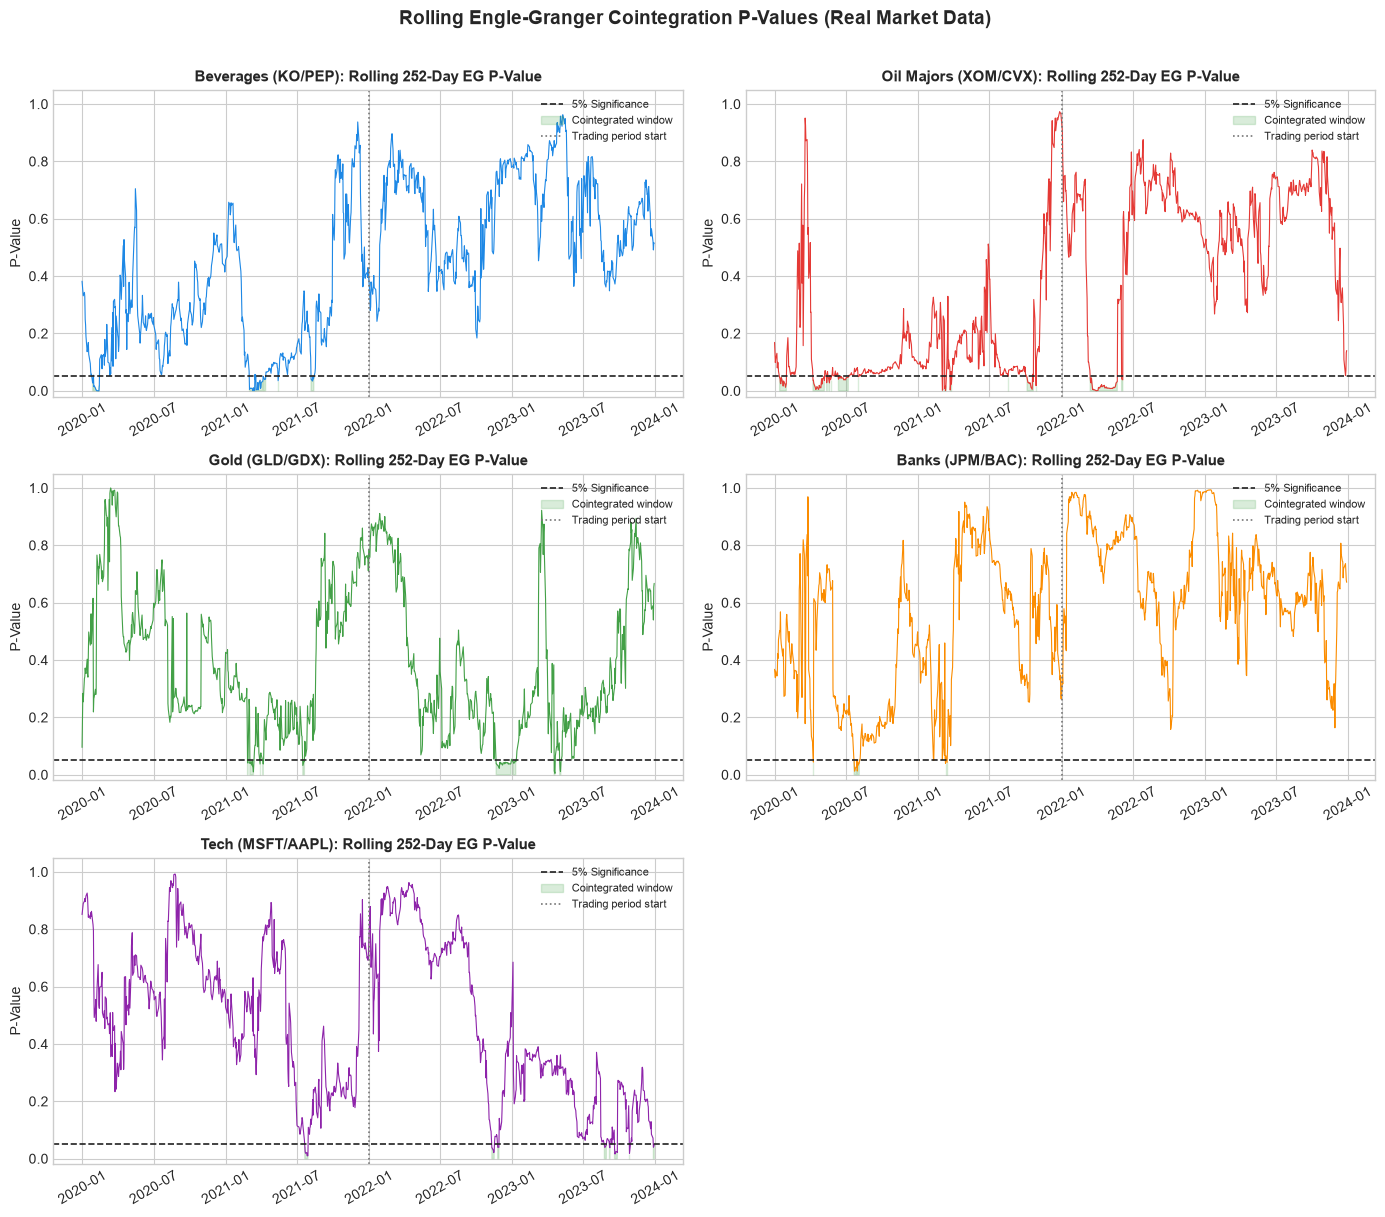


Fraction of rolling windows cointegrated (p < 0.05):
  Pair                        Formation    Trading      All
  → Beverages (KO/PEP)             9.1%       0.0%     4.6%
  → Oil Majors (XOM/CVX)          15.8%      10.2%    13.0%
  → Gold (GLD/GDX)                 3.2%       8.0%     5.6%
  ✗ Banks (JPM/BAC)                2.4%       0.0%     1.2%
  ✗ Tech (MSFT/AAPL)               1.4%       4.6%     3.0%


In [19]:
n_pairs = len(pairs_data)
n_rows = (n_pairs + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4 * n_rows))
axes_flat = axes.flatten()

for i, (pair_name, pvals) in enumerate(rolling_pvalues.items()):
    ax = axes_flat[i]
    pv = pvals.dropna()

    ax.plot(pv.index, pv, color=PAIR_COLORS[i], linewidth=0.8)
    ax.axhline(y=0.05, color=COLORS['dark'], linestyle='--', linewidth=1.2, label='5% Significance')
    ax.fill_between(pv.index, 0, pv, where=pv < 0.05,
                    alpha=0.2, color=COLORS['green'], label='Cointegrated window')
    ax.axvline(pd.Timestamp(TRADING_START), color=COLORS['grey'], linestyle=':', linewidth=1.2,
               label='Trading period start')

    ax.set_title(f'{pair_name}: Rolling {ROLL_WINDOW}-Day EG P-Value', fontsize=11, fontweight='bold')
    ax.set_ylabel('P-Value', fontsize=10)
    ax.set_ylim(-0.02, 1.05)
    ax.legend(fontsize=8, loc='upper right')
    ax.tick_params(axis='x', rotation=30)

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle(f'Rolling Engle-Granger Cointegration P-Values ({DATA_LABEL})',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("\nFraction of rolling windows cointegrated (p < 0.05):")
print(f"  {'Pair':<26s} {'Formation':>10s} {'Trading':>10s} {'All':>8s}")
for pair_name in pairs_data:
    pv = rolling_pvalues[pair_name].dropna()
    frac_form = (pv.loc[:FORMATION_END] < 0.05).mean()
    frac_trade = (pv.loc[TRADING_START:] < 0.05).mean()
    frac_all = (pv < 0.05).mean()
    label = "→" if pair_name in trade_pairs else "✗"
    print(f"  {label} {pair_name:<24s} {frac_form:>10.1%} {frac_trade:>10.1%} {frac_all:>8.1%}")

## 7. Half-Life Analysis

The **half-life of mean reversion** determines the expected duration of a trade:
$$\tau_{1/2} = \frac{\ln 2}{\theta} = -\frac{\ln 2}{\ln(1+b)}$$

Practical implications:
- **Short half-life** ($< 20$ days): Fast reversion, suited for short-term trading, but may
  generate excessive transaction costs
- **Moderate half-life** ($20-60$ days): Sweet spot for most pairs traders
- **Long half-life** ($> 60$ days): Slow reversion, requires patient capital and
  higher conviction

Rolling half-life estimates (trailing 252-day window, spread built from the formation
hedge ratio) reveal how the mean-reversion speed changes over time. Windows where the
spread shows no mean reversion ($b \geq 0$) have an infinite half-life and are shown as gaps.

In [20]:
rolling_halflife = {}

for pair_name in trade_pairs:
    s = spreads[pair_name].values
    n = len(s)
    hl = np.full(n, np.nan)

    for t in range(ROLL_WINDOW - 1, n):
        window = s[t - ROLL_WINDOW + 1:t + 1]
        b = OLS(np.diff(window), sm.add_constant(window[:-1])).fit().params[1]
        if -1 < b < 0:
            hl[t] = -np.log(2) / np.log(1 + b)

    rolling_halflife[pair_name] = pd.Series(hl, index=spreads[pair_name].index)

print("Rolling half-life estimates computed.")

Rolling half-life estimates computed.


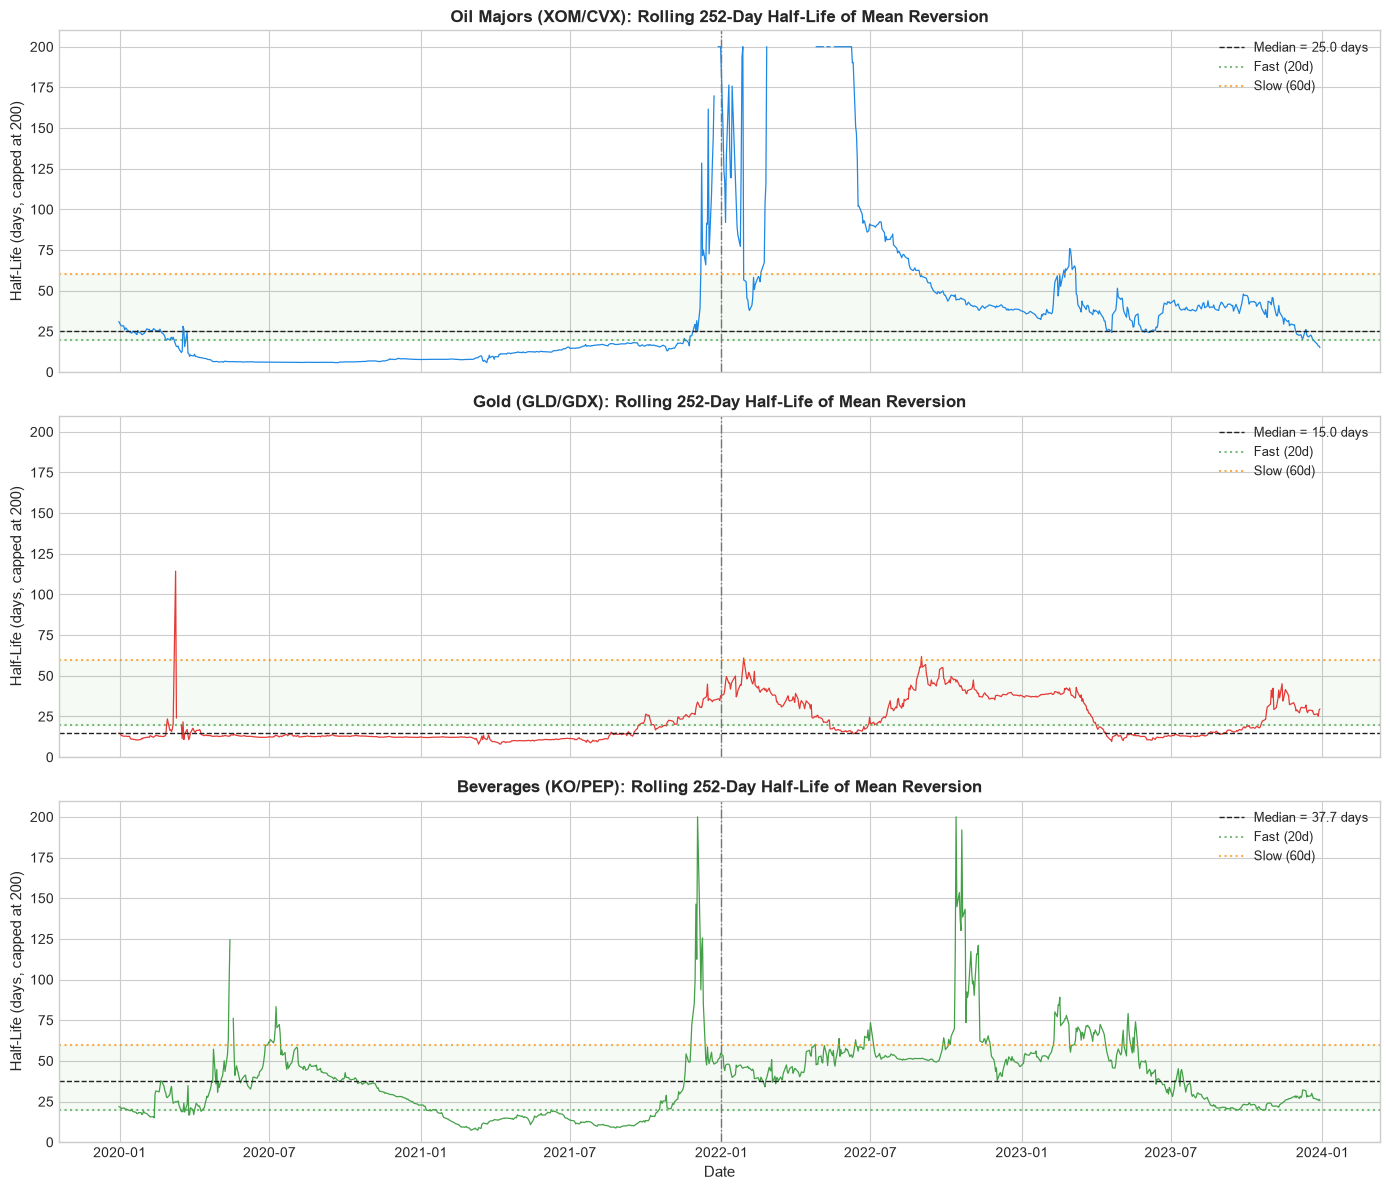


Rolling Half-Life Summary (trading days):
  Pair                      Formation Median  Trading Median    25th-75th pct  > 60 days   No MR
  Oil Majors (XOM/CVX)                   9.9            41.4         9.0-41.7      13.9%    4.4%
  Gold (GLD/GDX)                        12.7            31.0        12.5-32.6       0.3%    0.3%
  Beverages (KO/PEP)                    22.9            49.7        20.9-51.4      12.1%    0.1%


In [21]:
fig, axes = plt.subplots(len(trade_pairs), 1, figsize=(14, 4 * len(trade_pairs)), sharex=True)
if len(trade_pairs) == 1:
    axes = [axes]

for i, pair_name in enumerate(trade_pairs):
    ax = axes[i]
    hl = rolling_halflife[pair_name]

    ax.plot(hl.index, hl.clip(upper=200), color=PAIR_COLORS[i], linewidth=0.9)
    ax.axhline(y=hl.median(), color=COLORS['dark'], linestyle='--', linewidth=1,
               label=f'Median = {hl.median():.1f} days')
    ax.axhline(y=20, color=COLORS['green'], linestyle=':', alpha=0.7, label='Fast (20d)')
    ax.axhline(y=60, color=COLORS['orange'], linestyle=':', alpha=0.7, label='Slow (60d)')
    ax.axhspan(20, 60, alpha=0.05, color=COLORS['green'])
    ax.axvline(pd.Timestamp(TRADING_START), color=COLORS['grey'], linestyle='-.', linewidth=1)

    ax.set_title(f'{pair_name}: Rolling {ROLL_WINDOW}-Day Half-Life of Mean Reversion',
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Half-Life (days, capped at 200)', fontsize=11)
    ax.set_ylim(0, 210)
    ax.legend(fontsize=9, loc='upper right')

plt.xlabel('Date', fontsize=11)
plt.tight_layout()
plt.show()

print("\nRolling Half-Life Summary (trading days):")
print(f"  {'Pair':<24s} {'Formation Median':>17s} {'Trading Median':>15s} {'25th-75th pct':>16s} "
      f"{'> 60 days':>10s} {'No MR':>7s}")
for pair_name in trade_pairs:
    hl_all = rolling_halflife[pair_name].iloc[ROLL_WINDOW - 1:]
    hl = hl_all.dropna()
    q25, q75 = hl.quantile([0.25, 0.75])
    print(f"  {pair_name:<24s} {hl.loc[:FORMATION_END].median():>17.1f} "
          f"{hl.loc[TRADING_START:].median():>15.1f} {f'{q25:.1f}-{q75:.1f}':>16s} "
          f"{(hl > 60).mean():>10.1%} {hl_all.isna().mean():>7.1%}")

## 8. Regime Detection with Markov Switching

### Hidden Markov Model for Spread Dynamics

The spread may alternate between **regimes**:
- **Calm regime**: low volatility of spread changes (favourable for pairs trading)
- **Turbulent regime**: high volatility, where the spread can move far from equilibrium
  and stop-losses are more likely

With real market data, regime changes often correspond to identifiable macro events:
- COVID-19 crash (March 2020)
- Fed tightening cycles (2022–2023)
- Sector-specific disruptions (oil price war, bank stress)

A **Markov Switching regression** models daily spread changes as:
$$\Delta S_t = \mu_{s_t} + \sigma_{s_t} \varepsilon_t, \quad \varepsilon_t \sim N(0,1)$$

where $s_t \in \{0, 1\}$ is the hidden regime, following a Markov chain with
transition matrix:
$$P = \begin{pmatrix} p_{00} & p_{01} \\ p_{10} & p_{11} \end{pmatrix}, \qquad
p_{ij} = \Pr(s_{t+1} = j \mid s_t = i)$$

The expected duration of regime $i$ is $1 / (1 - p_{ii})$ days.

### Avoiding Look-Ahead Bias

- The model is **fitted on the formation period only**.
- The fitted parameters are then run through the Hamilton filter over the full sample
  to produce **filtered** probabilities $\Pr(s_t = j \mid \Delta S_1, \dots, \Delta S_t)$,
  which use only data up to day $t$.
- **Smoothed** probabilities $\Pr(s_t = j \mid \text{all data})$ use future data. They are
  shown for illustration only and are never used for trading decisions.
- Regime labels are assigned by variance: the regime with the larger $\sigma^2$ is the
  turbulent regime, regardless of how the optimizer numbered it.

In [22]:
demo_pair = trade_pairs[0]
spread_changes = spreads[demo_pair].diff().dropna()
spread_changes_form = spread_changes.loc[:FORMATION_END]

ms_model_form = MarkovRegression(spread_changes_form.values, k_regimes=2, trend='c',
                                 switching_variance=True)
ms_fit = ms_model_form.fit(search_reps=20, disp=False)

params = pd.Series(np.asarray(ms_fit.params), index=ms_model_form.param_names)
sigma2 = np.array([params['sigma2[0]'], params['sigma2[1]']])
const = np.array([params['const[0]'], params['const[1]']])
CALM, TURB = (0, 1) if sigma2[0] <= sigma2[1] else (1, 0)

transition = np.asarray(ms_fit.regime_transition)[:, :, 0]
p_stay = np.array([transition[0, 0], transition[1, 1]])
durations = 1 / (1 - p_stay)

print(f"Markov Switching Model — {demo_pair} (fitted on formation period, {DATA_LABEL})")
print("=" * 70)
for label, k in [('Calm', CALM), ('Turbulent', TURB)]:
    print(f"  {label:<10s} regime: mu = {const[k]:+.5f}, sigma = {np.sqrt(sigma2[k]):.5f}, "
          f"p(stay) = {p_stay[k]:.3f}, expected duration = {durations[k]:.1f} days")
print(f"\n  Log-likelihood: {ms_fit.llf:.2f}")

ms_model_full = MarkovRegression(spread_changes.values, k_regimes=2, trend='c', switching_variance=True)
ms_full = ms_model_full.smooth(ms_fit.params)

prob_turb_filtered = pd.Series(np.asarray(ms_full.filtered_marginal_probabilities)[:, TURB],
                               index=spread_changes.index)
prob_turb_smoothed = pd.Series(np.asarray(ms_full.smoothed_marginal_probabilities)[:, TURB],
                               index=spread_changes.index)

print(f"\n  Share of trading-period days classified turbulent (filtered > 0.5): "
      f"{(prob_turb_filtered.loc[TRADING_START:] > 0.5).mean():.1%}")

Markov Switching Model — Oil Majors (XOM/CVX) (fitted on formation period, Real Market Data)
  Calm       regime: mu = +0.01325, sigma = 0.59001, p(stay) = 0.982, expected duration = 56.2 days
  Turbulent  regime: mu = +0.07540, sigma = 2.34055, p(stay) = 0.846, expected duration = 6.5 days

  Log-likelihood: -833.40

  Share of trading-period days classified turbulent (filtered > 0.5): 22.4%


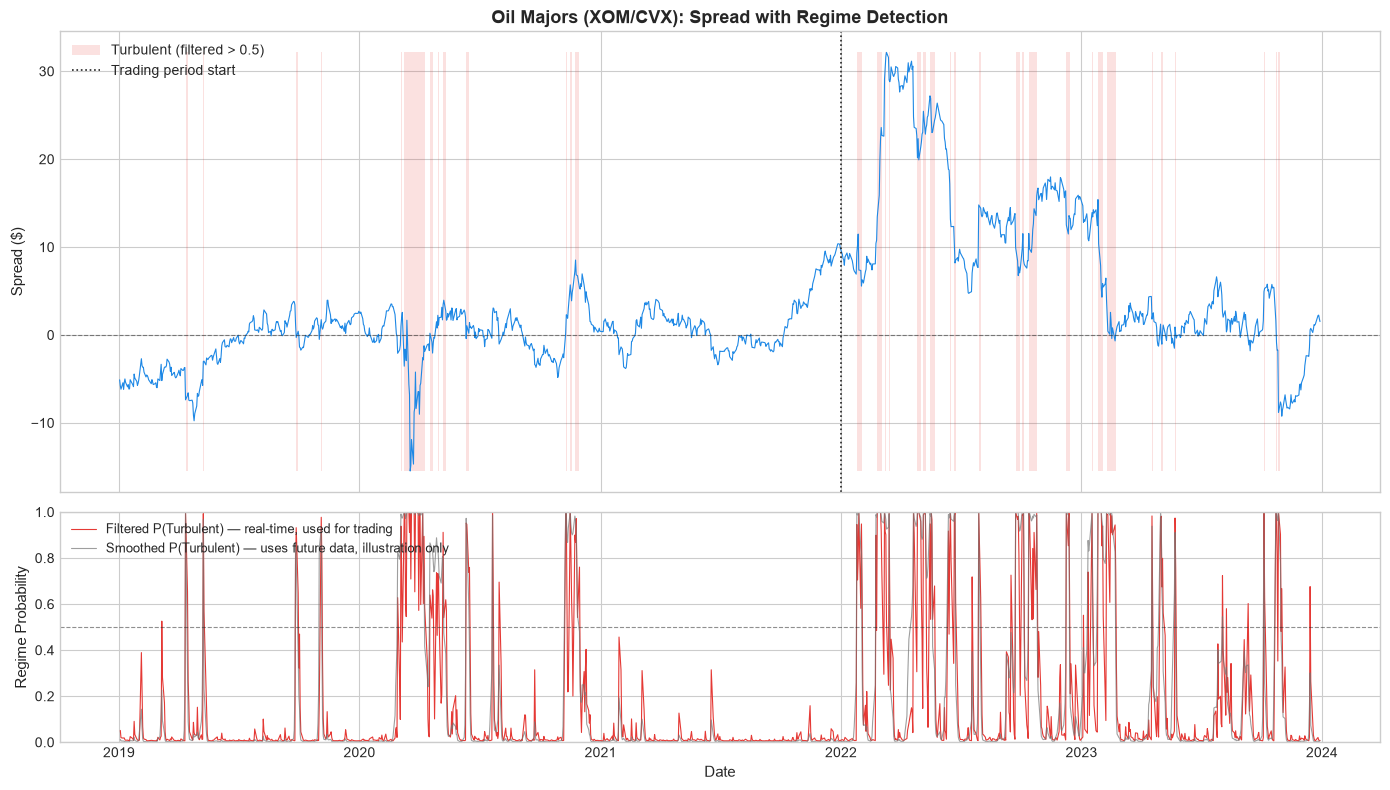

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

s = spreads[demo_pair]
ax1.plot(s.index, s, color=COLORS['blue'], linewidth=0.8)
ax1.axhline(y=s.loc[:FORMATION_END].mean(), color=COLORS['dark'], linestyle='--',
            linewidth=0.8, alpha=0.5)
turbulent = (prob_turb_filtered > 0.5).reindex(s.index, fill_value=False)
ax1.fill_between(s.index, s.min(), s.max(), where=turbulent, color=COLORS['red'],
                 alpha=0.15, linewidth=0, label='Turbulent (filtered > 0.5)')
ax1.axvline(pd.Timestamp(TRADING_START), color=COLORS['dark'], linestyle=':', linewidth=1.2,
            label='Trading period start')
ax1.set_title(f'{demo_pair}: Spread with Regime Detection', fontsize=13, fontweight='bold')
ax1.set_ylabel('Spread ($)', fontsize=11)
ax1.legend(fontsize=10, loc='upper left')

ax2.plot(prob_turb_filtered.index, prob_turb_filtered, color=COLORS['red'], linewidth=0.8,
         label='Filtered P(Turbulent) — real-time, used for trading')
ax2.plot(prob_turb_smoothed.index, prob_turb_smoothed, color=COLORS['grey'], linewidth=0.8,
         alpha=0.7, label='Smoothed P(Turbulent) — uses future data, illustration only')
ax2.axhline(y=0.5, color=COLORS['dark'], linestyle='--', linewidth=0.8, alpha=0.5)
ax2.set_ylim(0, 1)
ax2.set_ylabel('Regime Probability', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.legend(fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

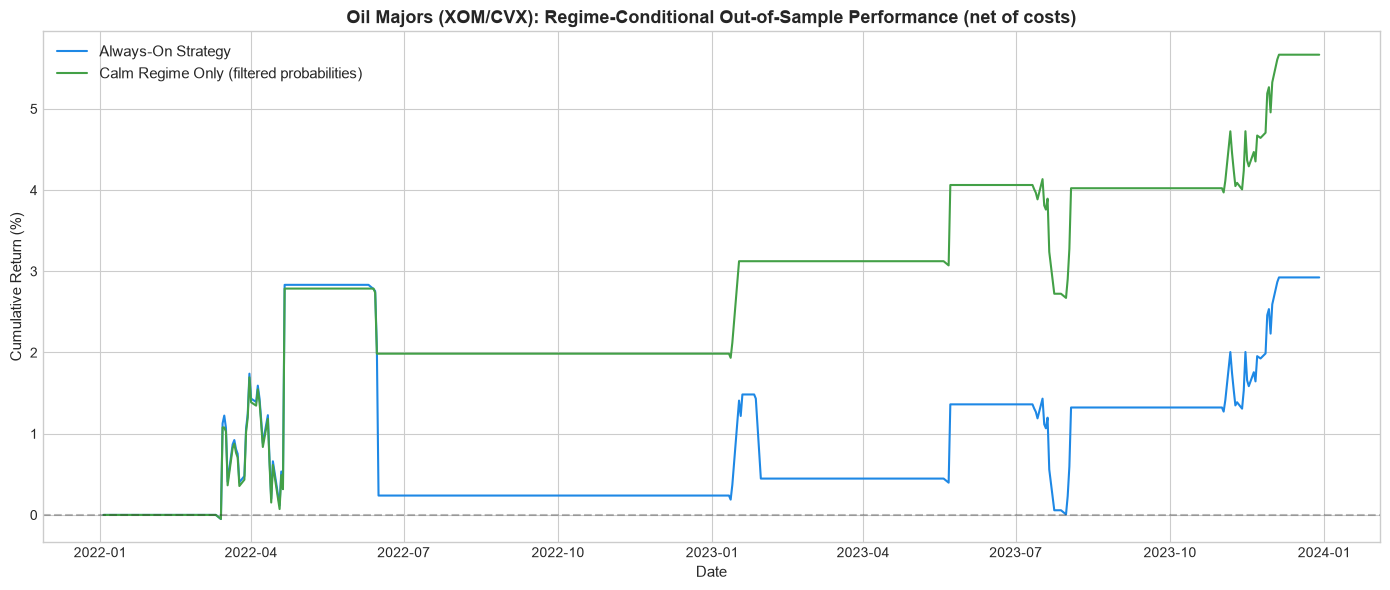


Oil Majors (XOM/CVX): Regime-Conditional Comparison (trading period, net of costs)
------------------------------------------------------------------------------------------
  Always-On                          CAGR=   1.46%  Vol=  3.20%  Sharpe=  0.47  MaxDD=  -2.75%
  Calm Regime Only                   CAGR=   2.81%  Vol=  2.83%  Sharpe=  0.99  MaxDD=  -1.59%


In [24]:
calm_flag = (prob_turb_filtered <= 0.5).reindex(spreads[demo_pair].index, fill_value=True)
calm_trade = calm_flag.loc[TRADING_START:]

pos_always = positions[demo_pair]
pos_regime = pos_always.where(calm_trade, 0.0)

ret_always = strategy_returns[demo_pair]
ret_regime, _ = strategy_returns_from(spreads[demo_pair].loc[TRADING_START:],
                                      gross_exposure[demo_pair].loc[TRADING_START:], pos_regime)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(ret_always.index, ((1 + ret_always).cumprod() - 1) * 100, color=COLORS['blue'],
        linewidth=1.5, label='Always-On Strategy')
ax.plot(ret_regime.index, ((1 + ret_regime).cumprod() - 1) * 100, color=COLORS['green'],
        linewidth=1.5, label='Calm Regime Only (filtered probabilities)')
ax.axhline(y=0, color=COLORS['dark'], linestyle='--', alpha=0.3)
ax.set_title(f'{demo_pair}: Regime-Conditional Out-of-Sample Performance (net of costs)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Cumulative Return (%)', fontsize=11)
ax.set_xlabel('Date', fontsize=11)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


def quick_metrics(r, name):
    equity = (1 + r).cumprod()
    ann_ret = equity.iloc[-1] ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    sharpe = r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan
    dd = (equity / equity.cummax() - 1).min()
    print(f"  {name:<34s} CAGR={ann_ret:>8.2%}  Vol={ann_vol:>7.2%}  "
          f"Sharpe={sharpe:>6.2f}  MaxDD={dd:>8.2%}")


print(f"\n{demo_pair}: Regime-Conditional Comparison (trading period, net of costs)")
print("-" * 90)
quick_metrics(ret_always, "Always-On")
quick_metrics(ret_regime, "Calm Regime Only")

## 9. Monte Carlo Robustness Testing

To assess whether the out-of-sample performance is **statistically significant** and not
a product of luck, two Monte Carlo exercises are run on the demonstration pair. Each
simulated spread path has the same length as the trading period (plus a 60-day warm-up
for the z-score), and the strategy is applied with **exactly the same rules, return
definition, gross exposure and transaction costs** as the real backtest, so the
simulated Sharpe ratios are directly comparable with the observed one.

1. **Bootstrap null (no mean reversion)**: Daily spread changes from the trading period
   are resampled with replacement. This keeps their volatility and fat tails but
   destroys any mean reversion, producing a random-walk spread. If the observed Sharpe
   ratio sits far in the right tail of this distribution, the profits are unlikely to
   be luck. The one-sided p-value is
   $\;p = \frac{1 + \#\{\text{SR}_{\text{boot}} \ge \text{SR}_{\text{obs}}\}}{1 + N}$.

2. **OU model check**: Paths are simulated from the OU process estimated in the formation
   period. This shows the Sharpe ratio the strategy *should* earn if the formation-period
   model had continued to hold. An observed Sharpe ratio well below this distribution
   indicates the relationship weakened out of sample.

The **risk of a large drawdown** is estimated from the drawdowns of the simulated
strategy equity curves (not of the spread itself).

In [25]:
N_MC = 1000
DD_THRESHOLD = -0.10

demo_ou = ou_params[demo_pair]
spread_trade = spreads[demo_pair].loc[TRADING_START:]
gross_trade = gross_exposure[demo_pair].loc[TRADING_START:]
n_trade = len(spread_trade)
n_path = n_trade + LOOKBACK

obs_ret = strategy_returns[demo_pair]
obs_sharpe = obs_ret.mean() / obs_ret.std() * np.sqrt(252) if obs_ret.std() > 0 else 0.0
obs_equity = (1 + obs_ret).cumprod()
obs_maxdd = (obs_equity / obs_equity.cummax() - 1).min()

spread_rets = spread_trade.diff().dropna().values


def simulate_strategy(path):
    path_series = pd.Series(path)
    z = rolling_zscore(path_series).iloc[LOOKBACK:].reset_index(drop=True)
    s = path_series.iloc[LOOKBACK:].reset_index(drop=True)
    g = pd.Series(gross_trade.values)
    pos = generate_signals(z)
    net, _ = strategy_returns_from(s, g, pos)
    sharpe = net.mean() / net.std() * np.sqrt(252) if net.std() > 0 else 0.0
    equity = (1 + net).cumprod()
    maxdd = (equity / equity.cummax() - 1).min()
    return sharpe, maxdd


sharpe_bootstrap = np.zeros(N_MC)
maxdd_bootstrap = np.zeros(N_MC)
sharpe_ou_sim = np.zeros(N_MC)
maxdd_ou_sim = np.zeros(N_MC)

phi = demo_ou['phi']
mu_ou = demo_ou['mu']
sigma_e = demo_ou['resid_std']
start_level = spreads[demo_pair].loc[:FORMATION_END].iloc[-1]

print(f"Observed out-of-sample Sharpe ({demo_pair}): {obs_sharpe:.3f}")
print(f"Running {N_MC} Monte Carlo simulations...")

for mc in range(N_MC):
    boot = start_level + np.cumsum(np.random.choice(spread_rets, size=n_path, replace=True))
    sharpe_bootstrap[mc], maxdd_bootstrap[mc] = simulate_strategy(boot)

    shocks = np.random.randn(n_path) * sigma_e
    ou_path = np.empty(n_path)
    ou_path[0] = mu_ou + shocks[0]
    for t in range(1, n_path):
        ou_path[t] = mu_ou + phi * (ou_path[t-1] - mu_ou) + shocks[t]
    sharpe_ou_sim[mc], maxdd_ou_sim[mc] = simulate_strategy(ou_path)

print("Monte Carlo simulation complete.")

Observed out-of-sample Sharpe (Oil Majors (XOM/CVX)): 0.469
Running 1000 Monte Carlo simulations...
Monte Carlo simulation complete.


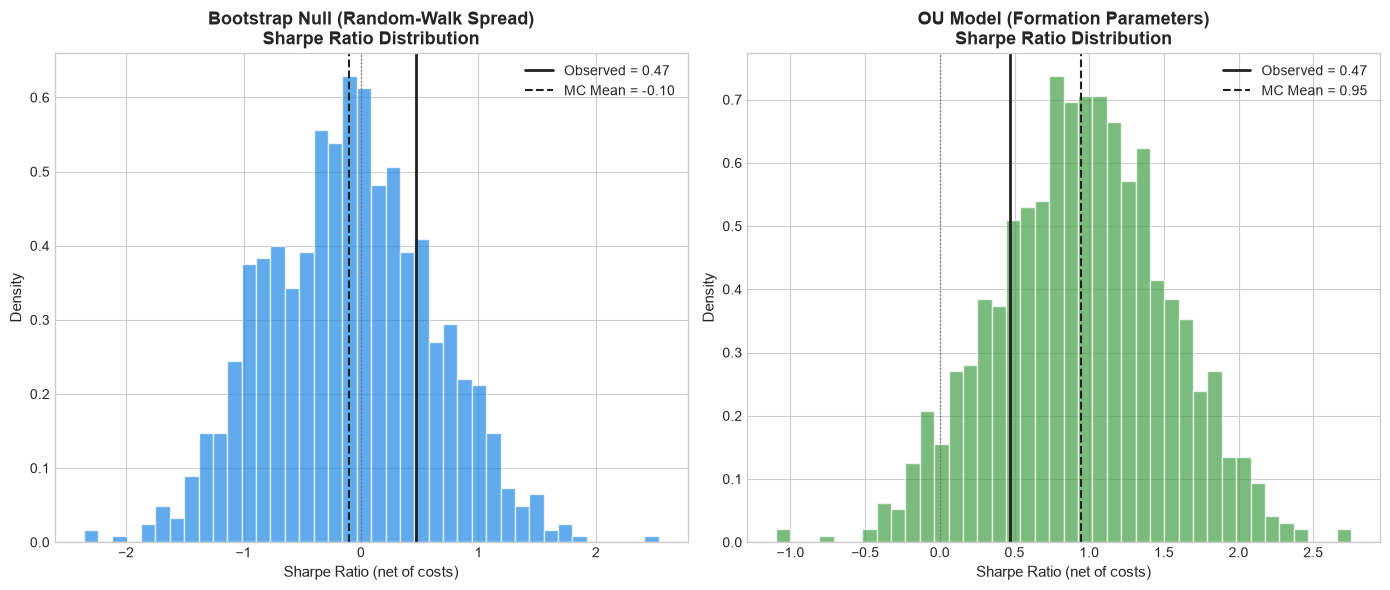

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for ax, dist, color, title in [
    (ax1, sharpe_bootstrap, COLORS['blue'], 'Bootstrap Null (Random-Walk Spread)'),
    (ax2, sharpe_ou_sim, COLORS['green'], 'OU Model (Formation Parameters)'),
]:
    ax.hist(dist, bins=40, color=color, alpha=0.7, edgecolor='white', density=True)
    ax.axvline(x=obs_sharpe, color=COLORS['dark'], linewidth=2, linestyle='-',
               label=f'Observed = {obs_sharpe:.2f}')
    ax.axvline(x=np.mean(dist), color=COLORS['dark'], linewidth=1.5, linestyle='--',
               label=f'MC Mean = {np.mean(dist):.2f}')
    ax.axvline(x=0, color=COLORS['grey'], linewidth=1, linestyle=':')
    ax.set_title(f'{title}\nSharpe Ratio Distribution', fontsize=13, fontweight='bold')
    ax.set_xlabel('Sharpe Ratio (net of costs)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

In [27]:
print("=" * 70)
print(f"MONTE CARLO ROBUSTNESS ANALYSIS — {demo_pair} ({DATA_LABEL})")
print("=" * 70)
print(f"\nObserved out-of-sample Sharpe Ratio: {obs_sharpe:.3f}")
print(f"Observed out-of-sample Max Drawdown: {obs_maxdd:.2%}")

for label, sharpe_dist, dd_dist in [
    ('Bootstrap null (no mean reversion)', sharpe_bootstrap, maxdd_bootstrap),
    ('OU model (formation parameters)', sharpe_ou_sim, maxdd_ou_sim),
]:
    ci = np.percentile(sharpe_dist, [2.5, 97.5])
    p_value = (1 + np.sum(sharpe_dist >= obs_sharpe)) / (1 + N_MC)
    percentile = (sharpe_dist < obs_sharpe).mean()
    print(f"\n--- {label}, {N_MC} paths ---")
    print(f"  Mean / Median Sharpe:         {np.mean(sharpe_dist):.3f} / {np.median(sharpe_dist):.3f}")
    print(f"  95% interval:                 [{ci[0]:.3f}, {ci[1]:.3f}]")
    print(f"  P(Sharpe > 0):                {(sharpe_dist > 0).mean():.1%}")
    print(f"  Observed Sharpe percentile:   {percentile:.1%}")
    print(f"  One-sided p-value (SR ≥ obs): {p_value:.4f}")
    print(f"  Median max drawdown:          {np.median(dd_dist):.2%}")
    print(f"  P(Max drawdown < {DD_THRESHOLD:.0%}):     {(dd_dist < DD_THRESHOLD).mean():.1%}")

MONTE CARLO ROBUSTNESS ANALYSIS — Oil Majors (XOM/CVX) (Real Market Data)

Observed out-of-sample Sharpe Ratio: 0.469
Observed out-of-sample Max Drawdown: -2.75%

--- Bootstrap null (no mean reversion), 1000 paths ---
  Mean / Median Sharpe:         -0.098 / -0.098
  95% interval:                 [-1.409, 1.266]
  P(Sharpe > 0):                44.0%
  Observed Sharpe percentile:   78.6%
  One-sided p-value (SR ≥ obs): 0.2148
  Median max drawdown:          -8.04%
  P(Max drawdown < -10%):     33.9%

--- OU model (formation parameters), 1000 paths ---
  Mean / Median Sharpe:         0.946 / 0.948
  95% interval:                 [-0.142, 2.037]
  P(Sharpe > 0):                94.8%
  Observed Sharpe percentile:   20.3%
  One-sided p-value (SR ≥ obs): 0.7972
  Median max drawdown:          -3.00%
  P(Max drawdown < -10%):     0.0%


## 10. Multi-Pair Portfolio

Combining multiple pairs into an equal-weighted portfolio provides **diversification**
benefits: individual pair strategies may have low or even negative correlations with
each other, reducing overall portfolio volatility and improving the Sharpe ratio.

The portfolio allocates equal capital to each traded pair and is rebalanced daily.
All figures are out-of-sample and net of transaction costs.

The diversification benefit depends on how correlated the underlying economic drivers
are across pairs. For example:
- **KO/PEP** and **XOM/CVX** should have low correlation (consumer staples vs energy)
- **JPM/BAC** may be moderately correlated with **XOM/CVX** (both macro-sensitive)

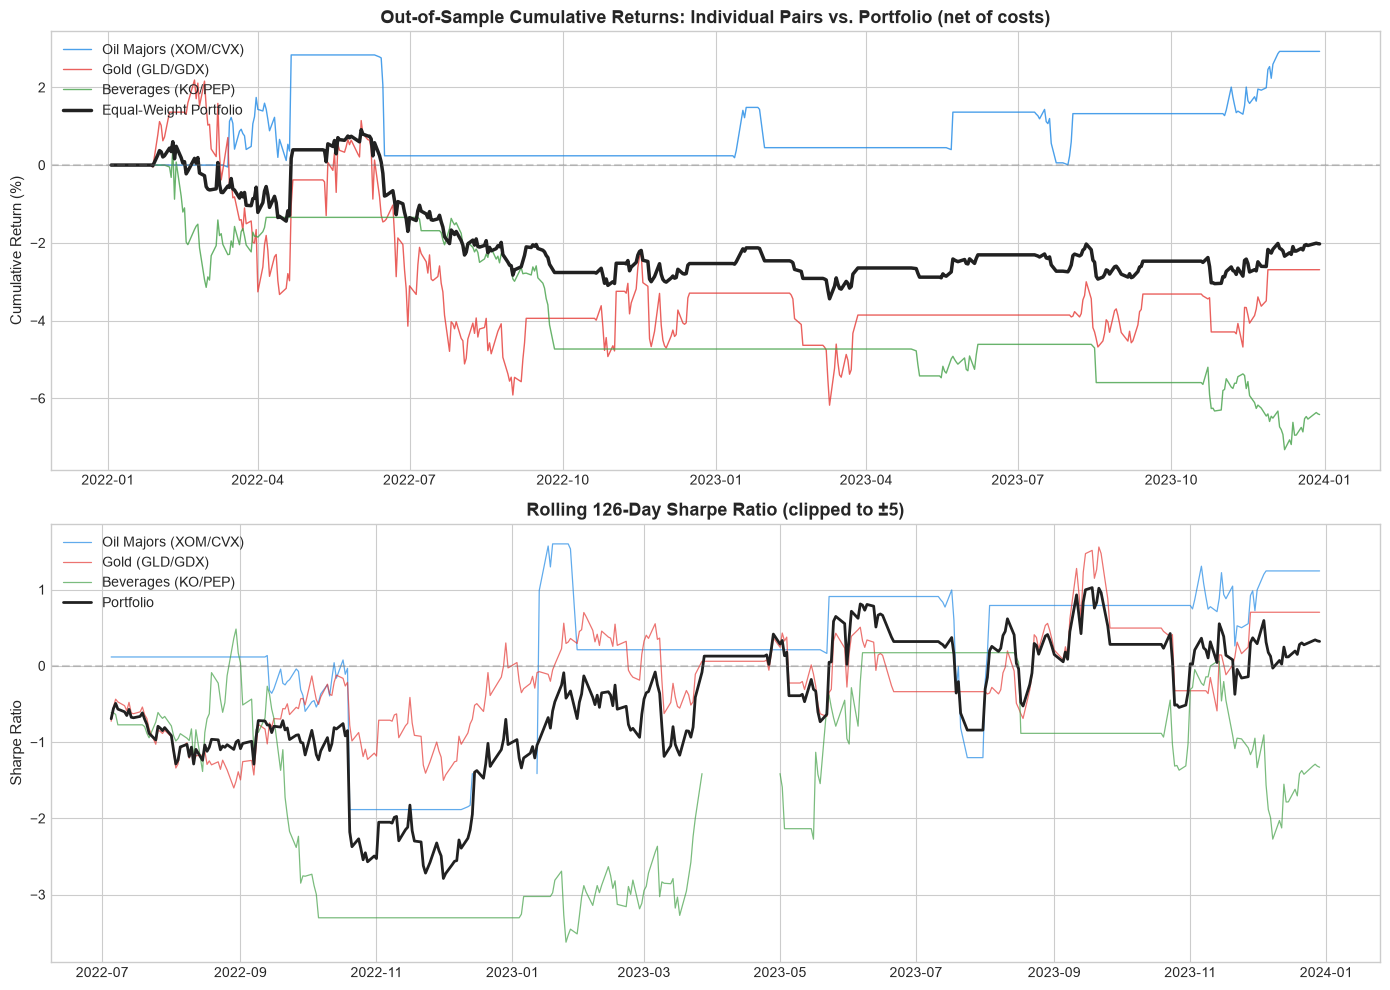

In [28]:
returns_df = pd.DataFrame({pair_name: strategy_returns[pair_name] for pair_name in trade_pairs})
portfolio_ret = returns_df.mean(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

for i, pair_name in enumerate(trade_pairs):
    equity = (1 + returns_df[pair_name]).cumprod() - 1
    ax1.plot(equity.index, equity * 100, color=PAIR_COLORS[i], linewidth=1, alpha=0.8, label=pair_name)

portfolio_equity = (1 + portfolio_ret).cumprod() - 1
ax1.plot(portfolio_equity.index, portfolio_equity * 100, color=COLORS['dark'], linewidth=2.5,
         label='Equal-Weight Portfolio')
ax1.axhline(y=0, color=COLORS['grey'], linestyle='--', alpha=0.3)
ax1.set_title('Out-of-Sample Cumulative Returns: Individual Pairs vs. Portfolio (net of costs)',
              fontsize=13, fontweight='bold')
ax1.set_ylabel('Cumulative Return (%)', fontsize=11)
ax1.legend(fontsize=10, loc='upper left')

ROLL_SHARPE = 126
for i, pair_name in enumerate(trade_pairs):
    r = returns_df[pair_name]
    rolling_sharpe = r.rolling(ROLL_SHARPE).mean() / r.rolling(ROLL_SHARPE).std() * np.sqrt(252)
    ax2.plot(rolling_sharpe.index, rolling_sharpe.clip(-5, 5), color=PAIR_COLORS[i],
             linewidth=0.9, alpha=0.7, label=pair_name)

port_roll_sharpe = (portfolio_ret.rolling(ROLL_SHARPE).mean()
                    / portfolio_ret.rolling(ROLL_SHARPE).std() * np.sqrt(252))
ax2.plot(port_roll_sharpe.index, port_roll_sharpe.clip(-5, 5), color=COLORS['dark'],
         linewidth=2, label='Portfolio')
ax2.axhline(y=0, color=COLORS['grey'], linestyle='--', alpha=0.3)
ax2.set_title(f'Rolling {ROLL_SHARPE}-Day Sharpe Ratio (clipped to ±5)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Sharpe Ratio', fontsize=11)
ax2.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()

In [29]:
def summary_row(r):
    equity = (1 + r).cumprod()
    cagr = equity.iloc[-1] ** (252 / len(r)) - 1
    vol = r.std() * np.sqrt(252)
    sharpe = r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan
    dd = (equity / equity.cummax() - 1).min()
    return cagr, vol, sharpe, dd


print("=" * 85)
print(f"INDIVIDUAL PAIRS vs. PORTFOLIO — OUT-OF-SAMPLE, NET OF COSTS ({DATA_LABEL})")
print("=" * 85)
print(f"{'Strategy':<35s} {'CAGR':>10s} {'Ann. Vol':>10s} {'Sharpe':>8s} {'Max DD':>10s}")
print("-" * 85)

for pair_name in trade_pairs:
    cagr, vol, sharpe, dd = summary_row(returns_df[pair_name])
    tag = '' if pair_name in coint_pairs else ' *'
    print(f"{pair_name + tag:<35s} {cagr:>10.2%} {vol:>10.2%} {sharpe:>8.2f} {dd:>10.2%}")

cagr, vol, sharpe, dd = summary_row(portfolio_ret)
print("-" * 85)
print(f"{'Equal-Weight Portfolio':<35s} {cagr:>10.2%} {vol:>10.2%} {sharpe:>8.2f} {dd:>10.2%}")
if candidate_pairs:
    print("\n* candidate pair: not cointegrated at 5% in the formation period")

individual_vols = returns_df.std() * np.sqrt(252)
diversification_ratio = individual_vols.mean() / vol if vol > 0 else 0
print(f"\nDiversification Ratio (avg. pair vol / portfolio vol): {diversification_ratio:.2f}x")

INDIVIDUAL PAIRS vs. PORTFOLIO — OUT-OF-SAMPLE, NET OF COSTS (Real Market Data)
Strategy                                  CAGR   Ann. Vol   Sharpe     Max DD
-------------------------------------------------------------------------------------
Oil Majors (XOM/CVX) *                   1.46%      3.20%     0.47     -2.75%
Gold (GLD/GDX) *                        -1.36%      5.96%    -0.20     -8.19%
Beverages (KO/PEP) *                    -3.28%      2.88%    -1.14     -7.73%
-------------------------------------------------------------------------------------
Equal-Weight Portfolio                  -1.03%      2.61%    -0.38     -4.31%

* candidate pair: not cointegrated at 5% in the formation period

Diversification Ratio (avg. pair vol / portfolio vol): 1.54x


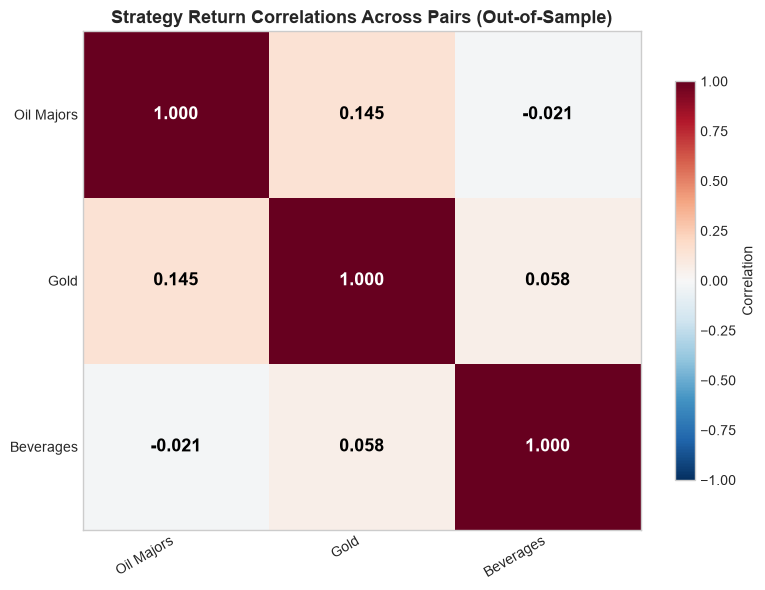


Average pairwise correlation of strategy returns: 0.060


In [30]:
fig, ax = plt.subplots(figsize=(8, 6))

corr_matrix = returns_df.corr()
im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(trade_pairs)))
ax.set_yticks(range(len(trade_pairs)))
short_labels = [p.split('(')[0].strip() if '(' in p else p for p in trade_pairs]
ax.set_xticklabels(short_labels, fontsize=10, rotation=30, ha='right')
ax.set_yticklabels(short_labels, fontsize=10)
ax.grid(False)

for i in range(len(trade_pairs)):
    for j in range(len(trade_pairs)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=13,
                fontweight='bold', color='white' if abs(val) > 0.5 else 'black')

plt.colorbar(im, ax=ax, shrink=0.8, label='Correlation')
ax.set_title('Strategy Return Correlations Across Pairs (Out-of-Sample)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

off_diag = corr_matrix.values[~np.eye(len(trade_pairs), dtype=bool)]
print(f"\nAverage pairwise correlation of strategy returns: {off_diag.mean():.3f}")

## 11. Conclusions & Practical Considerations

> The figures quoted below come from the run on real Yahoo Finance data (2019–2023).
> Adjusted prices are revised by Yahoo Finance when new dividends are paid, so re-running
> the notebook can shift the numbers slightly. If the notebook falls back to synthetic
> data, these conclusions do not apply.

### Key Findings

1. **None of the five economically motivated pairs is cointegrated at 5% in the
   formation period.** Using the correct Engle-Granger (MacKinnon) critical values, the
   closest pair is XOM/CVX (p ≈ 0.07), followed by GLD/GDX (p ≈ 0.14) and KO/PEP
   (p ≈ 0.34). The Johansen trace test agrees and rejects $r = 0$ for no pair. A strong
   economic story and high return correlation (0.74–0.91) do not guarantee a
   stationary spread.

2. **Cointegration is unstable.** Rolling 252-day tests find cointegration in only a
   small fraction of windows for every pair, and the share changes between the formation
   and trading periods. The XOM/CVX spread blew out during the 2022 energy shock, and its
   rolling half-life jumped from under 20 days to well above 100 days. A hedge ratio
   estimated in 2019–2021 did not describe 2022.

3. **Out-of-sample results are weak, as the tests predicted.** Trading the three
   candidate pairs in 2022–2023 with formation-period parameters and 10 bps round-trip
   costs gives Sharpe ratios of roughly +0.5 (XOM/CVX), −0.2 (GLD/GDX) and −1.1
   (KO/PEP). The equal-weight portfolio loses a little money (Sharpe ≈ −0.4). This is
   the expected outcome when pairs that are not cointegrated are traded as if they were.

4. **The best pair's profit is not statistically significant.** For XOM/CVX, the
   observed Sharpe ratio sits at about the 79th percentile of the bootstrap null
   (random-walk spread), a one-sided p-value of about 0.21. It also sits at about the
   20th percentile of the distribution implied by the formation-period OU model,
   another sign that mean reversion weakened out of sample.

5. **A real-time regime filter helped the demonstration pair.** Holding XOM/CVX
   positions only when the *filtered* Markov-switching probability indicates the calm
   regime raised the out-of-sample Sharpe ratio from about 0.5 to about 1.0 and reduced
   the maximum drawdown from about −2.8% to about −1.6%. This rests on a handful of
   trades on a single pair, so it is suggestive rather than conclusive.

6. **Diversification lowers volatility but cannot create an edge.** Strategy returns
   across pairs are nearly uncorrelated (average correlation ≈ 0.06) and the portfolio
   volatility is about 1.5x lower than the average pair, but combining pairs with zero or
   negative expected returns still produces a portfolio with no positive expected return.

### Methodological Corrections Relative to a Naive Backtest

- **Correct critical values**: plain ADF critical values (≈ −2.86 at 5%) applied to
  regression residuals overstate cointegration; the Engle-Granger value is ≈ −3.34.
- **No look-ahead in parameters**: hedge ratios, OU parameters and the regime model are
  estimated on 2019–2021 only and applied unchanged to 2022–2023.
- **No look-ahead in regimes**: trading uses filtered, not smoothed, regime probabilities.
- **Real return units**: returns are a percentage of gross exposure, not spread changes
  scaled by a rolling standard deviation, so CAGR, volatility and drawdown are meaningful.
- **Transaction costs** are deducted on every position change.
- **Trade-level statistics** (win rate, trade count, trade P&L) are computed per trade,
  not per day.

### Practical Considerations

- **Execution risk**: Slippage, market impact, and borrow costs for short selling
  erode returns, especially for small spreads.
- **Margin requirements**: Maintaining both long and short positions requires
  capital allocation for margin.
- **Crowding**: Pairs trading is a well-known strategy; popular pairs may exhibit
  reduced alpha due to crowding effects.
- **Multiple testing**: Screening many candidate pairs and keeping the best p-values
  inflates false discoveries. A broad pair search should adjust for this (e.g.
  Bonferroni or false-discovery-rate control).
- **Cointegration breakdowns**: As shown in Section 6, cointegration is not
  permanent. Continuous monitoring and periodic re-estimation are essential.

### Extensions

- **Kalman filter** for a dynamic, time-varying hedge ratio $\beta_t$
- **Walk-forward re-estimation** (e.g., re-fit the hedge ratio every quarter)
- **Log-price spreads** so that the hedge ratio is expressed in return terms
- **Machine learning** for pair selection (clustering, autoencoders on returns)
- **Copula-based approaches** for modeling non-linear dependence
- **Risk parity** weighting instead of equal weighting across pairs
- **Higher-frequency data** for intraday pairs trading

---

*This notebook uses adjusted daily closing prices from Yahoo Finance (KO, PEP, XOM, CVX,
GLD, GDX, JPM, BAC, MSFT, AAPL) from 2019 to 2023, with 2019–2021 as the formation period
and 2022–2023 as the out-of-sample trading period. If Yahoo Finance is unavailable, the
notebook falls back to synthetic data and labels every result accordingly.*